<a href="https://colab.research.google.com/github/futuregunmulju/2026-Signals-and-Systems-Speech-Noise-Reduction/blob/experiment%2Fminju/Challenge1_Noise_Spectrum_Pattern_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Challenge 1 — Noise Spectrum & Pattern Analysis
### 9조 | 신호및시스템 · Speech Noise Reduction

**목적:** Train의 `Noisy − Clean`으로 실제 혼합 잡음을 추출하고, 주파수/시간 특성을 분석해 필터 설계 근거를 얻습니다.

**분석 전용 노트북**입니다. Test 입력을 처리하는 제출 노트북이 아닙니다. Train/Validation Clean은 분석에만 사용합니다.

**실행 순서:** Work 1 환경 → Work 2 데이터 → Work 3 메타데이터 → Work 4 대표 파형 → Work 5 전 유형 PSD → Work 6 대표 스펙트로그램 → Work 7 보고서 내보내기.

## Work 1. 환경 준비

Colab 기준입니다. 필요 시 아래 설치 셀을 실행하세요.

In [ ]:
%pip -q install numpy pandas scipy soundfile matplotlib tqdm

In [ ]:
from pathlib import Path
import os, zipfile, json
import numpy as np
import pandas as pd
import soundfile as sf
from scipy import signal
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display

FS = 16000
N_FFT = 512
HOP = 128
EPS = 1e-14
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .18})
print('Analysis settings:', FS, N_FFT, HOP)

Analysis settings: 16000 512 128


## Work 2. Drive 연결 및 데이터 경로

기존 탐색 노트북과 동일하게 `/content/drive/MyDrive/noise_reduction_challenge/train/samples.csv` 및 `validation/samples.csv`를 가정합니다. 경로가 다르면 `DATA_ROOT`만 수정하세요.

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_ROOT = Path('/content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge')
except ImportError:
    DATA_ROOT = Path('release/noise_reduction_challenge')

# 필요할 때 여기만 수정하세요.
# DATA_ROOT = Path('/content/drive/MyDrive/다른폴더/noise_reduction_challenge')
if not (DATA_ROOT / 'train' / 'samples.csv').is_file():
    raise FileNotFoundError(f'Train CSV를 찾을 수 없습니다: {DATA_ROOT / "train" / "samples.csv"}')

OUT = Path('/content/noise_analysis_results') if Path('/content').is_dir() else Path('noise_analysis_results')
OUT.mkdir(parents=True, exist_ok=True)
print('DATA_ROOT:', DATA_ROOT)
print('결과 폴더:', OUT)

Mounted at /content/drive
DATA_ROOT: /content/drive/MyDrive/연세대/신호및시스템/9조_noise_reduction_challenge
결과 폴더: /content/noise_analysis_results


In [ ]:
REQUIRED = ['segment_id', 'clean_path', 'noisy_path', 'sample_rate_hz',
            'num_samples', 'noise_category', 'noise_code', 'target_snr_db']

def load_csv(split):
    df = pd.read_csv(DATA_ROOT / split / 'samples.csv')
    missing = set(REQUIRED) - set(df.columns)
    if missing:
        raise ValueError(f'{split} CSV에 누락된 컬럼: {sorted(missing)}')
    return df

train = load_csv('train')
validation = load_csv('validation')
print(f'Train {len(train)} / Validation {len(validation)}')
display(train[REQUIRED].head(3))

Train 1296 / Validation 164


,segment_id,clean_path,noisy_path,sample_rate_hz,num_samples,noise_category,noise_code,target_snr_db
0,speaker020_utt01_seg0001,train/clean/speaker020_utt01_seg0001.wav,train/noisy/speaker020_utt01_seg0001_noisy.wav,16000,48000,aircraft_cockpit,buccaneer1,10.0
1,speaker020_utt01_seg0002,train/clean/speaker020_utt01_seg0002.wav,train/noisy/speaker020_utt01_seg0002_noisy.wav,16000,48000,traffic_vehicle,N046,15.0
2,speaker020_utt01_seg0003,train/clean/speaker020_utt01_seg0003.wav,train/noisy/speaker020_utt01_seg0003_noisy.wav,16000,48000,alarm_siren,N036,5.0


## Work 3. 노이즈 라벨과 데이터 분포 확인

노이즈 유형별 표본 수를 살피고, Train에 없는 라벨이 Validation에 있는지도 확인합니다.

In [ ]:
counts = (train.groupby(['noise_category', 'noise_code']).size()
          .rename('train_count').reset_index())
val_counts = (validation.groupby(['noise_category', 'noise_code']).size()
              .rename('validation_count').reset_index())
counts = counts.merge(val_counts, how='outer', on=['noise_category', 'noise_code']).fillna(0)
counts[['train_count', 'validation_count']] = counts[['train_count', 'validation_count']].astype(int)
display(counts.sort_values(['noise_category','noise_code']).reset_index(drop=True))
counts.to_csv(OUT / 'noise_counts.csv', index=False)
missing = sorted(set(validation.noise_category) - set(train.noise_category))
print('Train에 없는 Validation noise_category:', missing)

,noise_category,noise_code,train_count,validation_count
0,aircraft_cockpit,buccaneer1,37,5
1,aircraft_cockpit,buccaneer2,37,4
2,aircraft_cockpit,f16,37,5
3,alarm_siren,N030,5,0
4,alarm_siren,N031,3,1
...,...,...,...,...
83,wind,N074,5,0
84,wind,N075,38,5
85,wind,N076,4,0
86,wind,N077,37,5


Train에 없는 Validation noise_category: []


## Work 4. 대표 샘플: 파형 + 스펙트로그램 + PSD

`CATEGORY`를 원하는 라벨로 바꾸세요. Clean/Noisy가 정렬되어 있어야 `Noisy − Clean`이 의미가 있습니다. WAV 저장 오차와 clipping 가능성은 남습니다.

선택: aircraft_cockpit buccaneer1 speaker020_utt01_seg0001


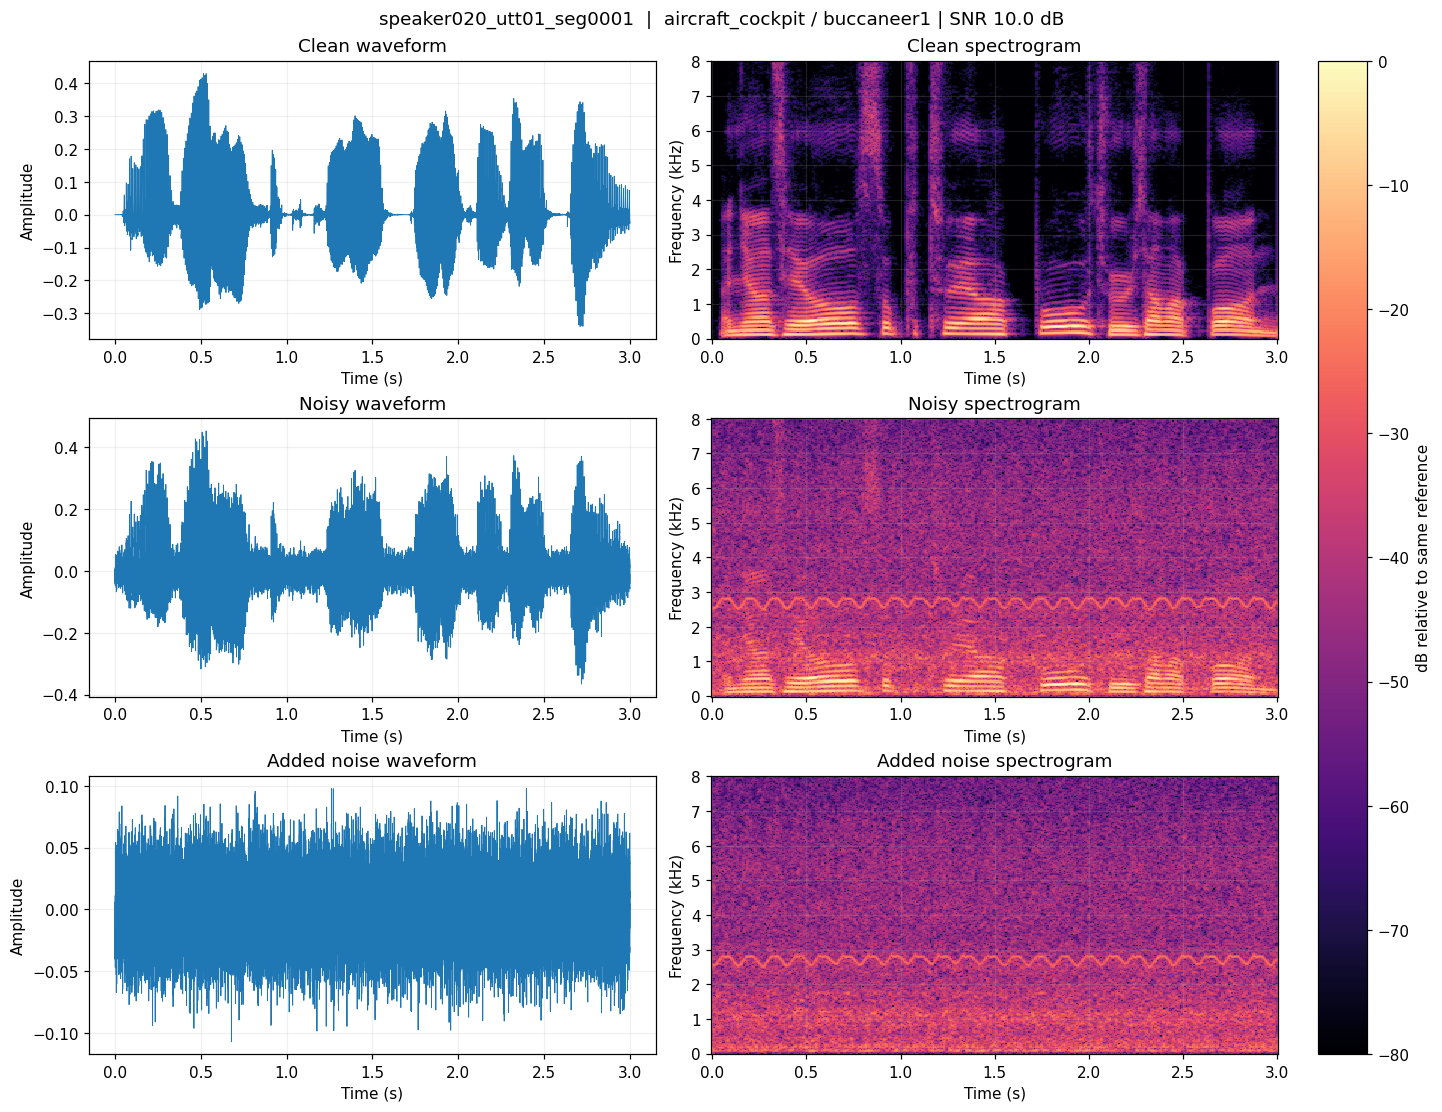

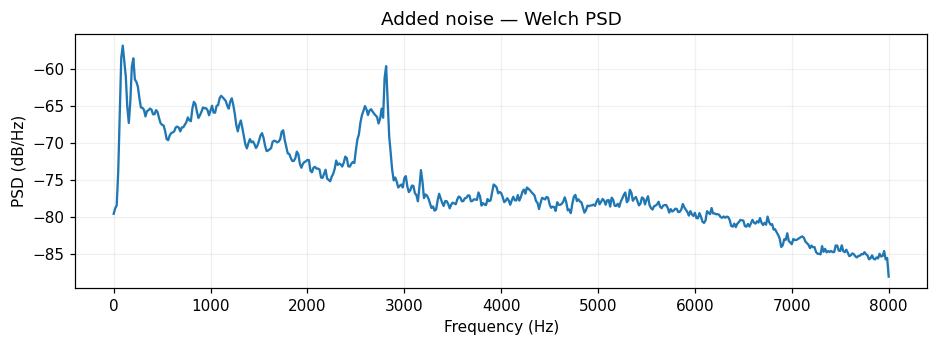

Noise RMS: 0.026403307660504124


In [ ]:
def load_pair(row):
    clean, sr1 = sf.read(DATA_ROOT / str(row['clean_path']), dtype='float64')
    noisy, sr2 = sf.read(DATA_ROOT / str(row['noisy_path']), dtype='float64')
    if sr1 != sr2 or sr1 != int(row['sample_rate_hz']) or sr1 != FS:
        raise ValueError(f'Unexpected sampling rate: {sr1}, {sr2}')
    if clean.ndim != 1 or noisy.ndim != 1 or clean.shape != noisy.shape:
        raise ValueError('Expected aligned mono WAV pair')
    if not np.isfinite(clean).all() or not np.isfinite(noisy).all():
        raise ValueError('NaN/Inf in audio')
    return clean, noisy, noisy-clean, sr1

def stft_mag(x, sr):
    f,t,z = signal.stft(x, fs=sr, window='hann', nperseg=N_FFT,
                        noverlap=N_FFT-HOP, nfft=N_FFT)
    return f,t,np.abs(z)

def plot_pair(row):
    clean,noisy,noise,sr = load_pair(row)
    waves = {'Clean':clean,'Noisy':noisy,'Added noise':noise}
    fig,ax = plt.subplots(3,2,figsize=(13,10),constrained_layout=True)
    mags = {k: stft_mag(v,sr) for k,v in waves.items()}
    ref = max(float(z.max()) for _,_,z in mags.values())
    for i,(name,x) in enumerate(waves.items()):
        time=np.arange(len(x))/sr
        ax[i,0].plot(time,x,lw=.6)
        ax[i,0].set(title=f'{name} waveform',xlabel='Time (s)',ylabel='Amplitude')
        f,t,mag=mags[name]
        db=20*np.log10(np.maximum(mag,ref*1e-6)/max(ref,EPS))
        im=ax[i,1].pcolormesh(t,f/1000,db,shading='auto',cmap='magma',vmin=-80,vmax=0)
        ax[i,1].set(title=f'{name} spectrogram',xlabel='Time (s)',ylabel='Frequency (kHz)')
    fig.colorbar(im,ax=ax[:,1],label='dB relative to same reference')
    fig.suptitle(f"{row['segment_id']}  |  {row['noise_category']} / {row['noise_code']} | SNR {row['target_snr_db']} dB")
    path=OUT/'sample_clean_noisy_noise.png';fig.savefig(path,bbox_inches='tight');plt.show();plt.close(fig)
    f,p=signal.welch(noise,fs=sr,nperseg=min(1024,len(noise)))
    fig,ax=plt.subplots(figsize=(10,3));ax.plot(f,10*np.log10(np.maximum(p,EPS)))
    ax.set(xlabel='Frequency (Hz)',ylabel='PSD (dB/Hz)',title='Added noise — Welch PSD')
    fig.savefig(OUT/'sample_noise_psd.png',bbox_inches='tight');plt.show();plt.close(fig)
    print('Noise RMS:',float(np.sqrt(np.mean(noise**2))))

CATEGORY = sorted(train.noise_category.unique())[0]  # 원하는 noise_category로 변경
subset = train[train.noise_category == CATEGORY]
row = subset.iloc[0]
print('선택:',row['noise_category'],row['noise_code'],row['segment_id'])
plot_pair(row)

## Work 5. 모든 노이즈 유형별 평균 PSD

**중요:** 파형 평균이 아닌 **파워 스펙트럼 평균**입니다. 파일별 Welch PSD를 구해 그룹별 평균을 냅니다. 크기 차이를 제거한 모양 비교도 함께 저장합니다.

`MAX_FILES_PER_CATEGORY=None`이면 Train 전부 분석합니다. 처음 실행할 때 10으로 낮춰도 됩니다. 분석 시에는 `noise_code`로 구분하면 같은 카테고리 안의 서로 다른 소리도 구별할 수 있습니다.

In [ ]:
MAX_FILES_PER_CATEGORY = None  # 빠른 테스트: 10, 전체 분석: None
GROUP_COLUMN = 'noise_code'  # 'noise_category'로 변경 가능
PSD_NPERSEG = 1024

rows=[]
psd_by_group={}
frequency=None
for group, group_df in tqdm(train.groupby(GROUP_COLUMN),desc='Noise groups'):
    if MAX_FILES_PER_CATEGORY is not None:
        group_df=group_df.head(MAX_FILES_PER_CATEGORY)
    spectra=[]; flatness=[]; stationarity=[]; rms_list=[]
    for _,r in group_df.iterrows():
        clean,noisy,noise,sr=load_pair(r)
        if len(noise)<PSD_NPERSEG: continue
        f,p=signal.welch(noise,fs=sr,window='hann',nperseg=PSD_NPERSEG,
                         noverlap=PSD_NPERSEG//2,scaling='density')
        if frequency is None: frequency=f
        spectra.append(p)
        rms_list.append(float(np.sqrt(np.mean(noise**2))))
        # Spectral flatness: 0이면 tonal, 1이면 white-like
        pos=np.maximum(p[1:],EPS)
        flatness.append(float(np.exp(np.mean(np.log(pos))) / np.mean(pos)))
        # 프레임 RMS 변동계수: 값이 크면 시간 변화가 큰 편
        frame_length=512
        count=len(noise)//frame_length
        if count>=2:
            frames=noise[:count*frame_length].reshape(count,frame_length)
            energy=np.sqrt(np.mean(frames**2,axis=1))
            stationarity.append(float(np.std(energy)/(np.mean(energy)+EPS)))
    if not spectra: continue
    mean_psd=np.mean(np.stack(spectra),axis=0)
    # 주파수 모양만 비교하도록 전체 파워로 정규화
    shape=mean_psd/(np.sum(mean_psd)+EPS)
    psd_by_group[str(group)]={'psd':mean_psd,'shape':shape}
    rows.append({'group':group,'files':len(spectra),
                 'rms_mean':np.mean(rms_list),'spectral_flatness_mean':np.mean(flatness),
                 'rms_variation_mean':np.mean(stationarity),
                 'peak_hz':float(f[np.argmax(mean_psd[1:])+1])})

summary=pd.DataFrame(rows).sort_values('group')
if summary.empty: raise RuntimeError('분석할 WAV가 없습니다. 경로와 파일을 확인하세요.')
summary.to_csv(OUT/'noise_summary.csv',index=False)
print('분석 그룹 수:',len(summary));display(summary)

Noise groups:   0%|          | 0/88 [00:00<?, ?it/s]

분석 그룹 수: 88


,group,files,rms_mean,spectral_flatness_mean,rms_variation_mean,peak_hz
0,N018,19,0.023637,0.103709,0.661620,3000.000
1,N019,16,0.025028,0.517506,0.388554,1093.750
2,N020,21,0.021948,0.010577,0.289630,62.500
3,N021,18,0.017550,0.021023,0.351400,62.500
4,N022,20,0.018225,0.189262,0.415740,375.000
...,...,...,...,...,...,...
83,m109,18,0.028195,0.031422,0.212327,62.500
84,machinegun,3,0.018480,0.000469,1.520664,125.000
85,pink,37,0.035150,0.417370,0.114706,15.625
86,volvo,19,0.026016,0.000141,0.387700,15.625


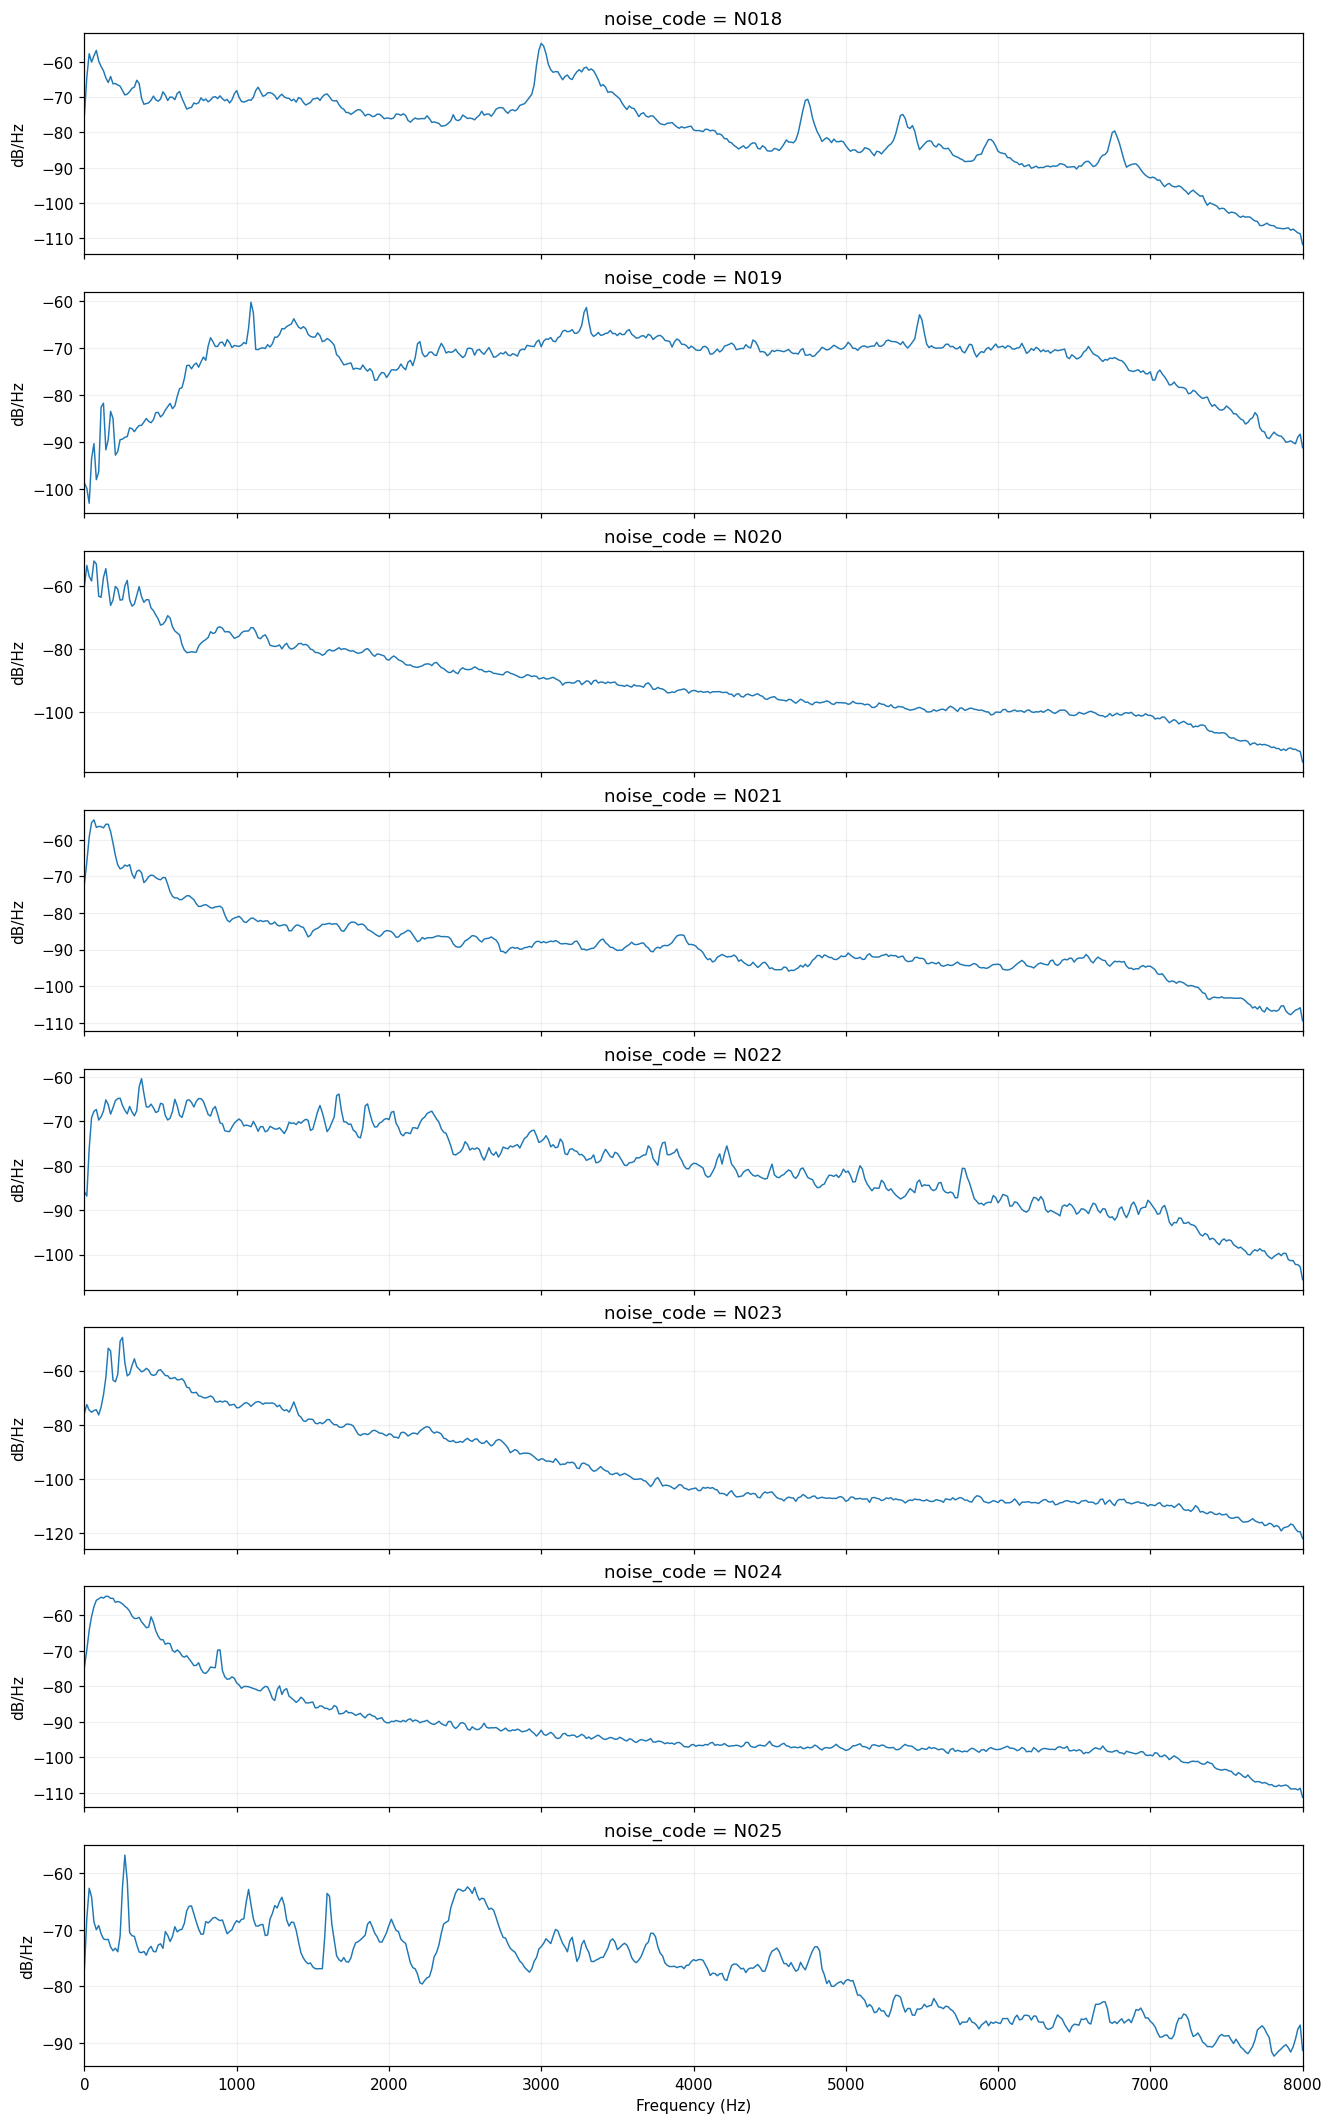

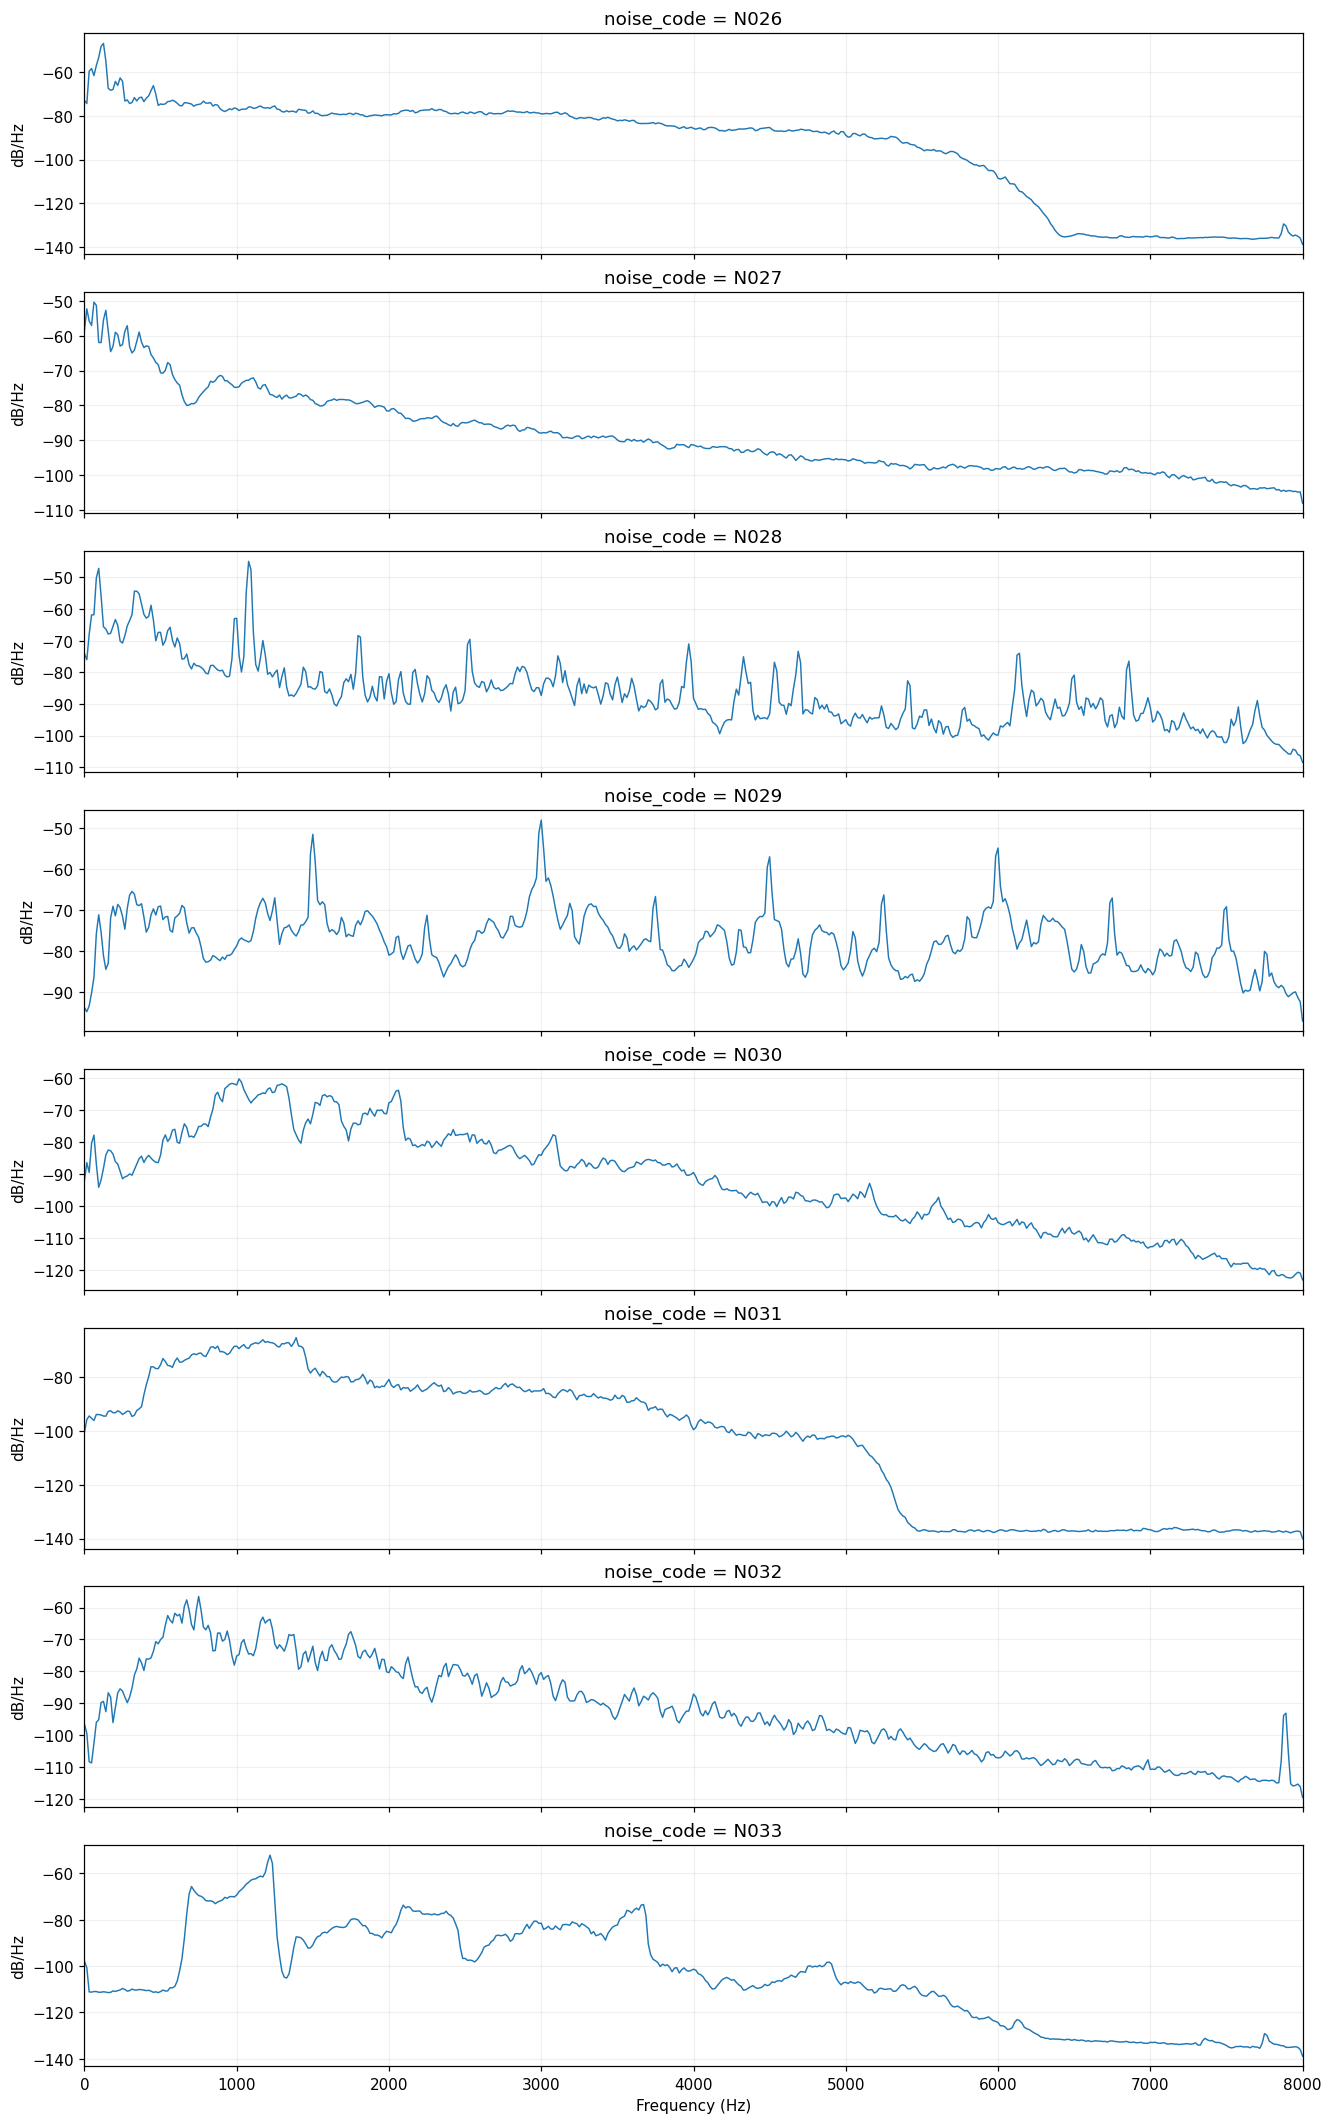

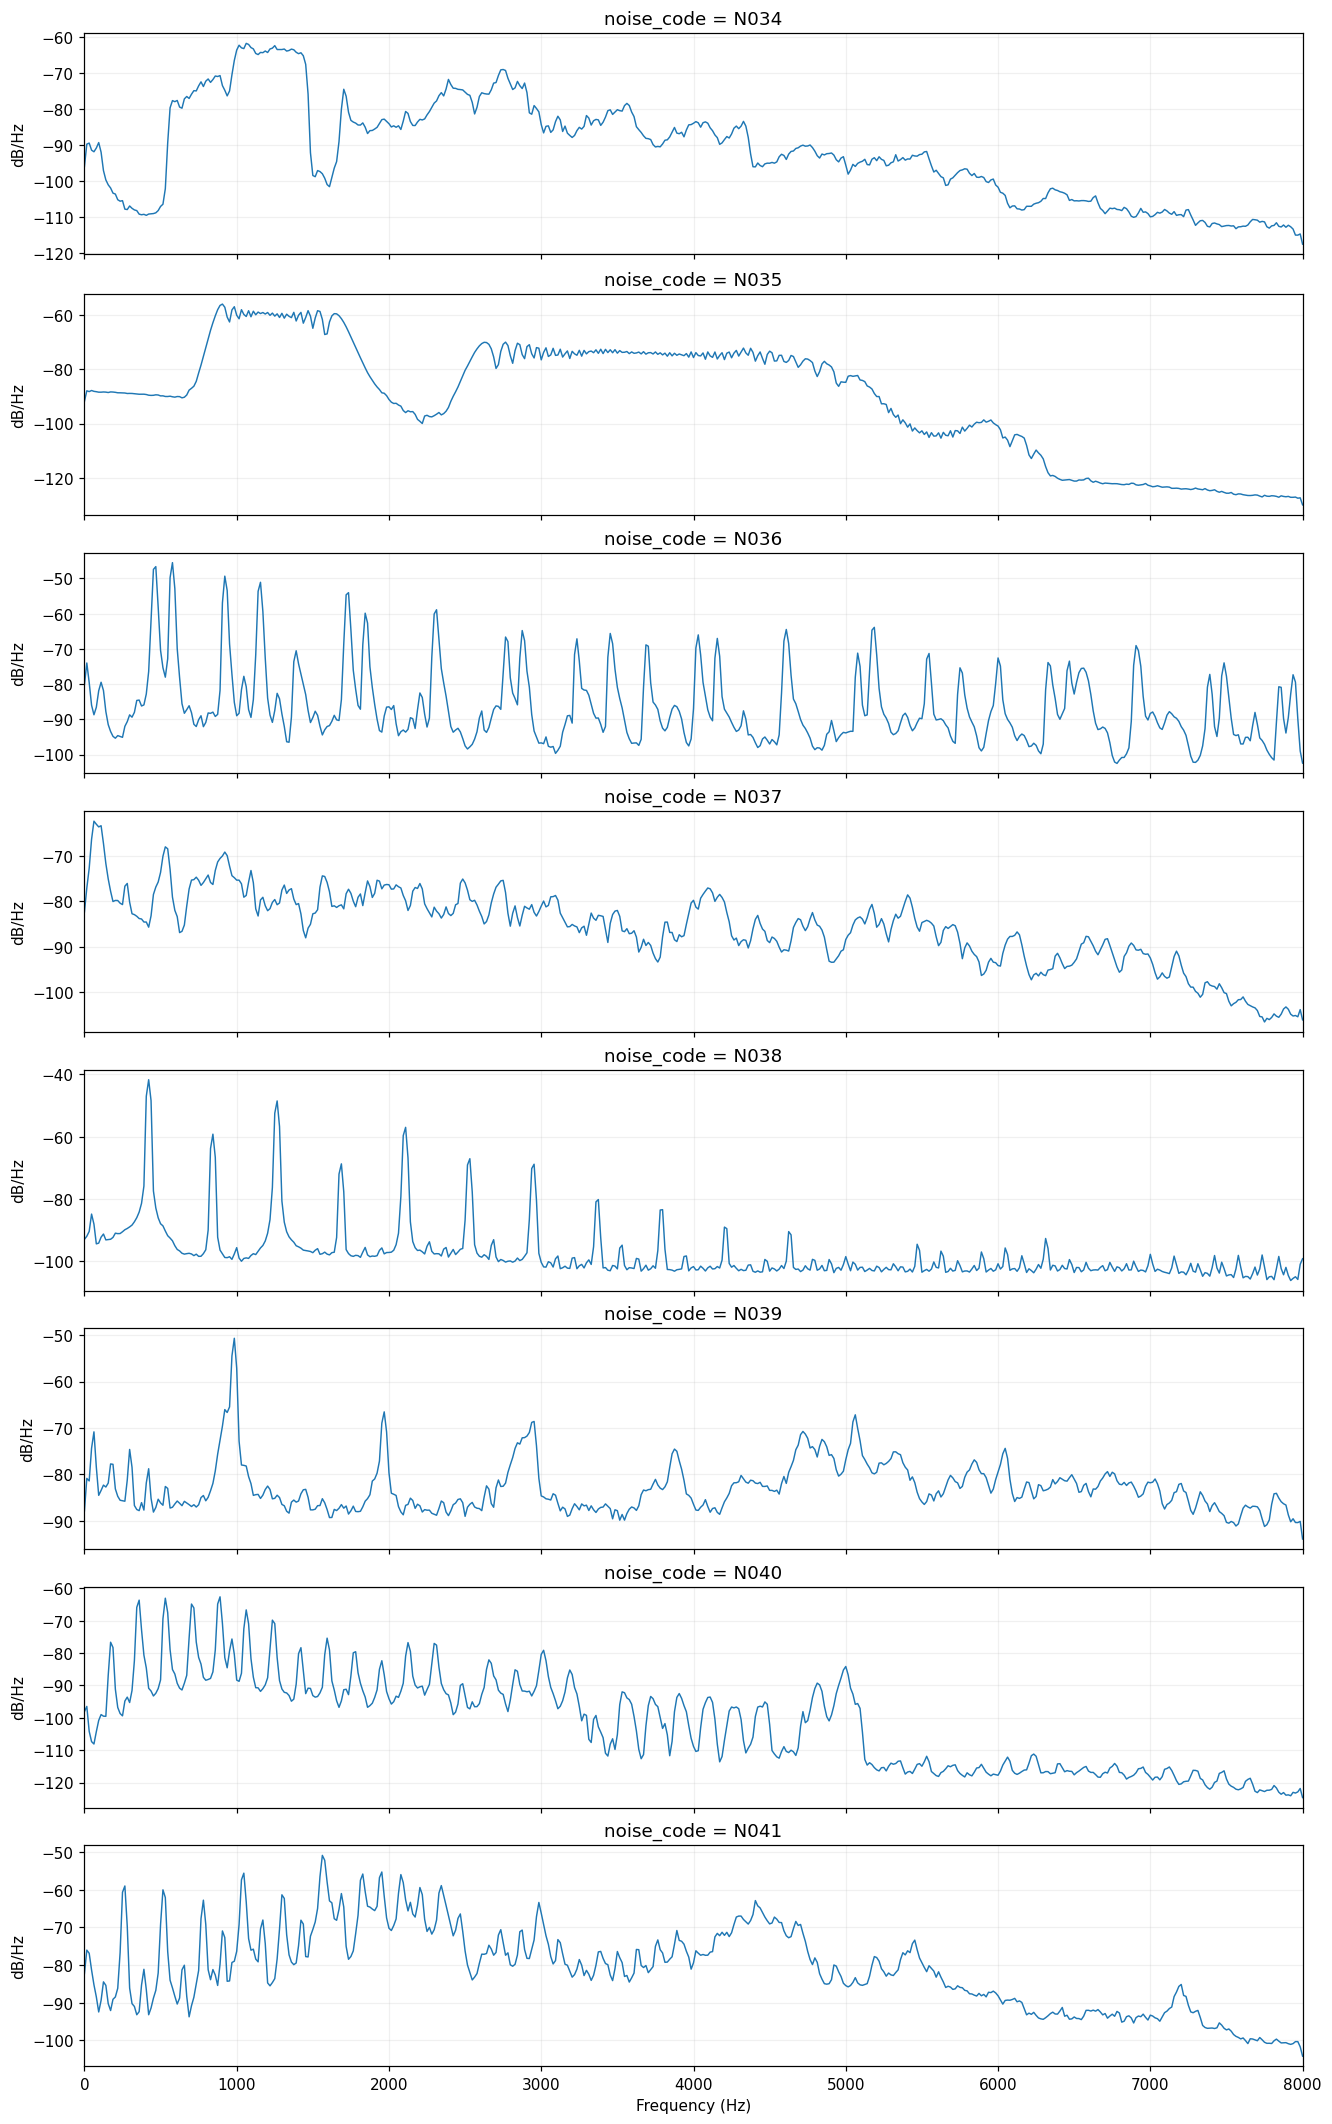

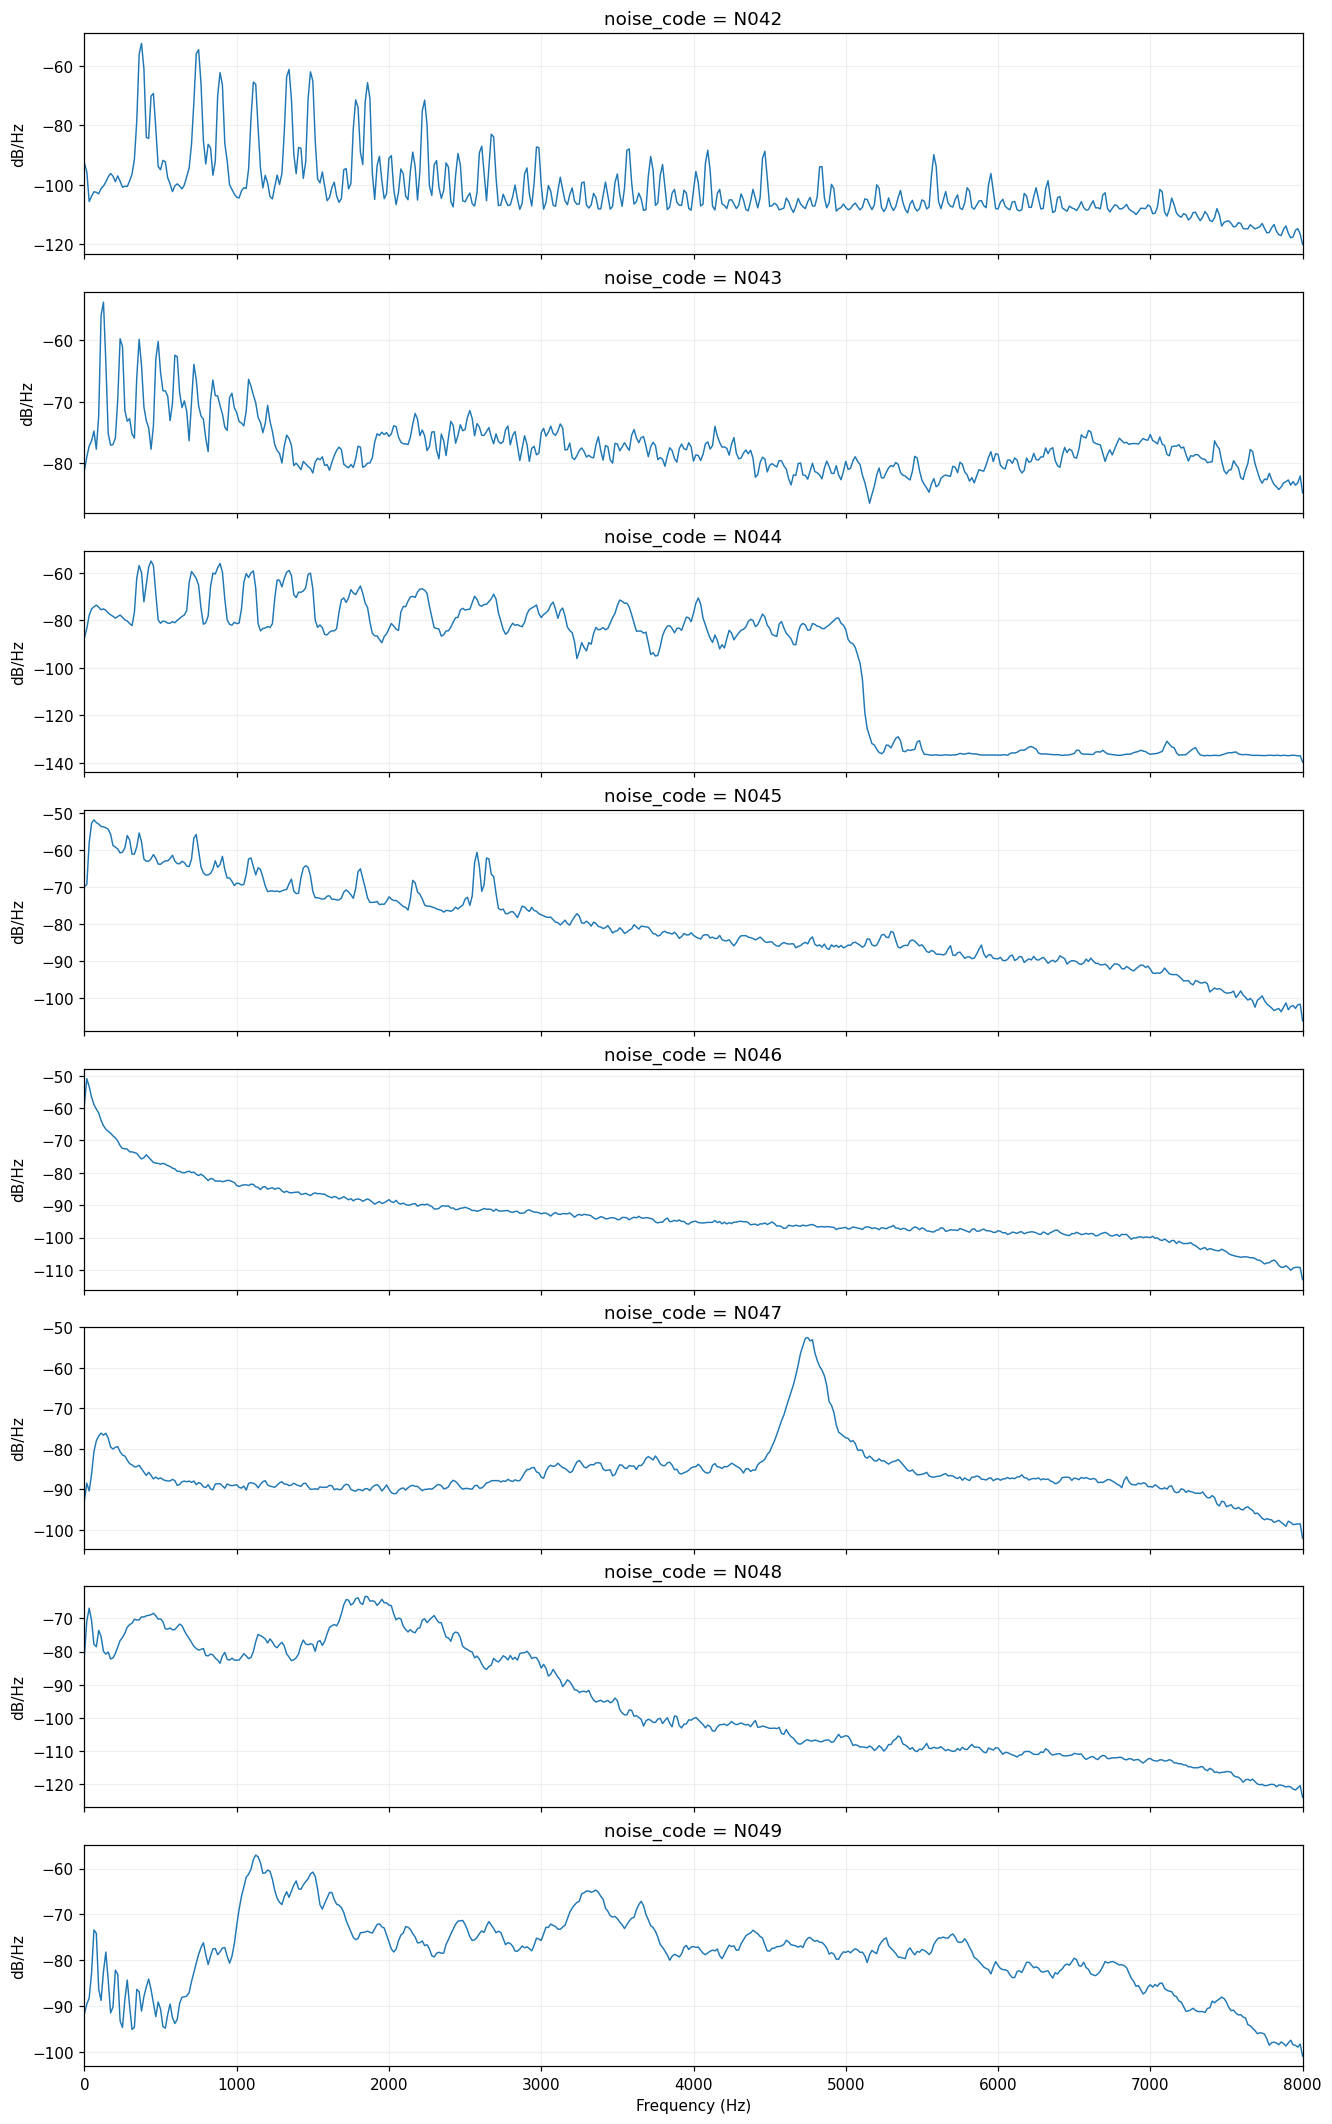

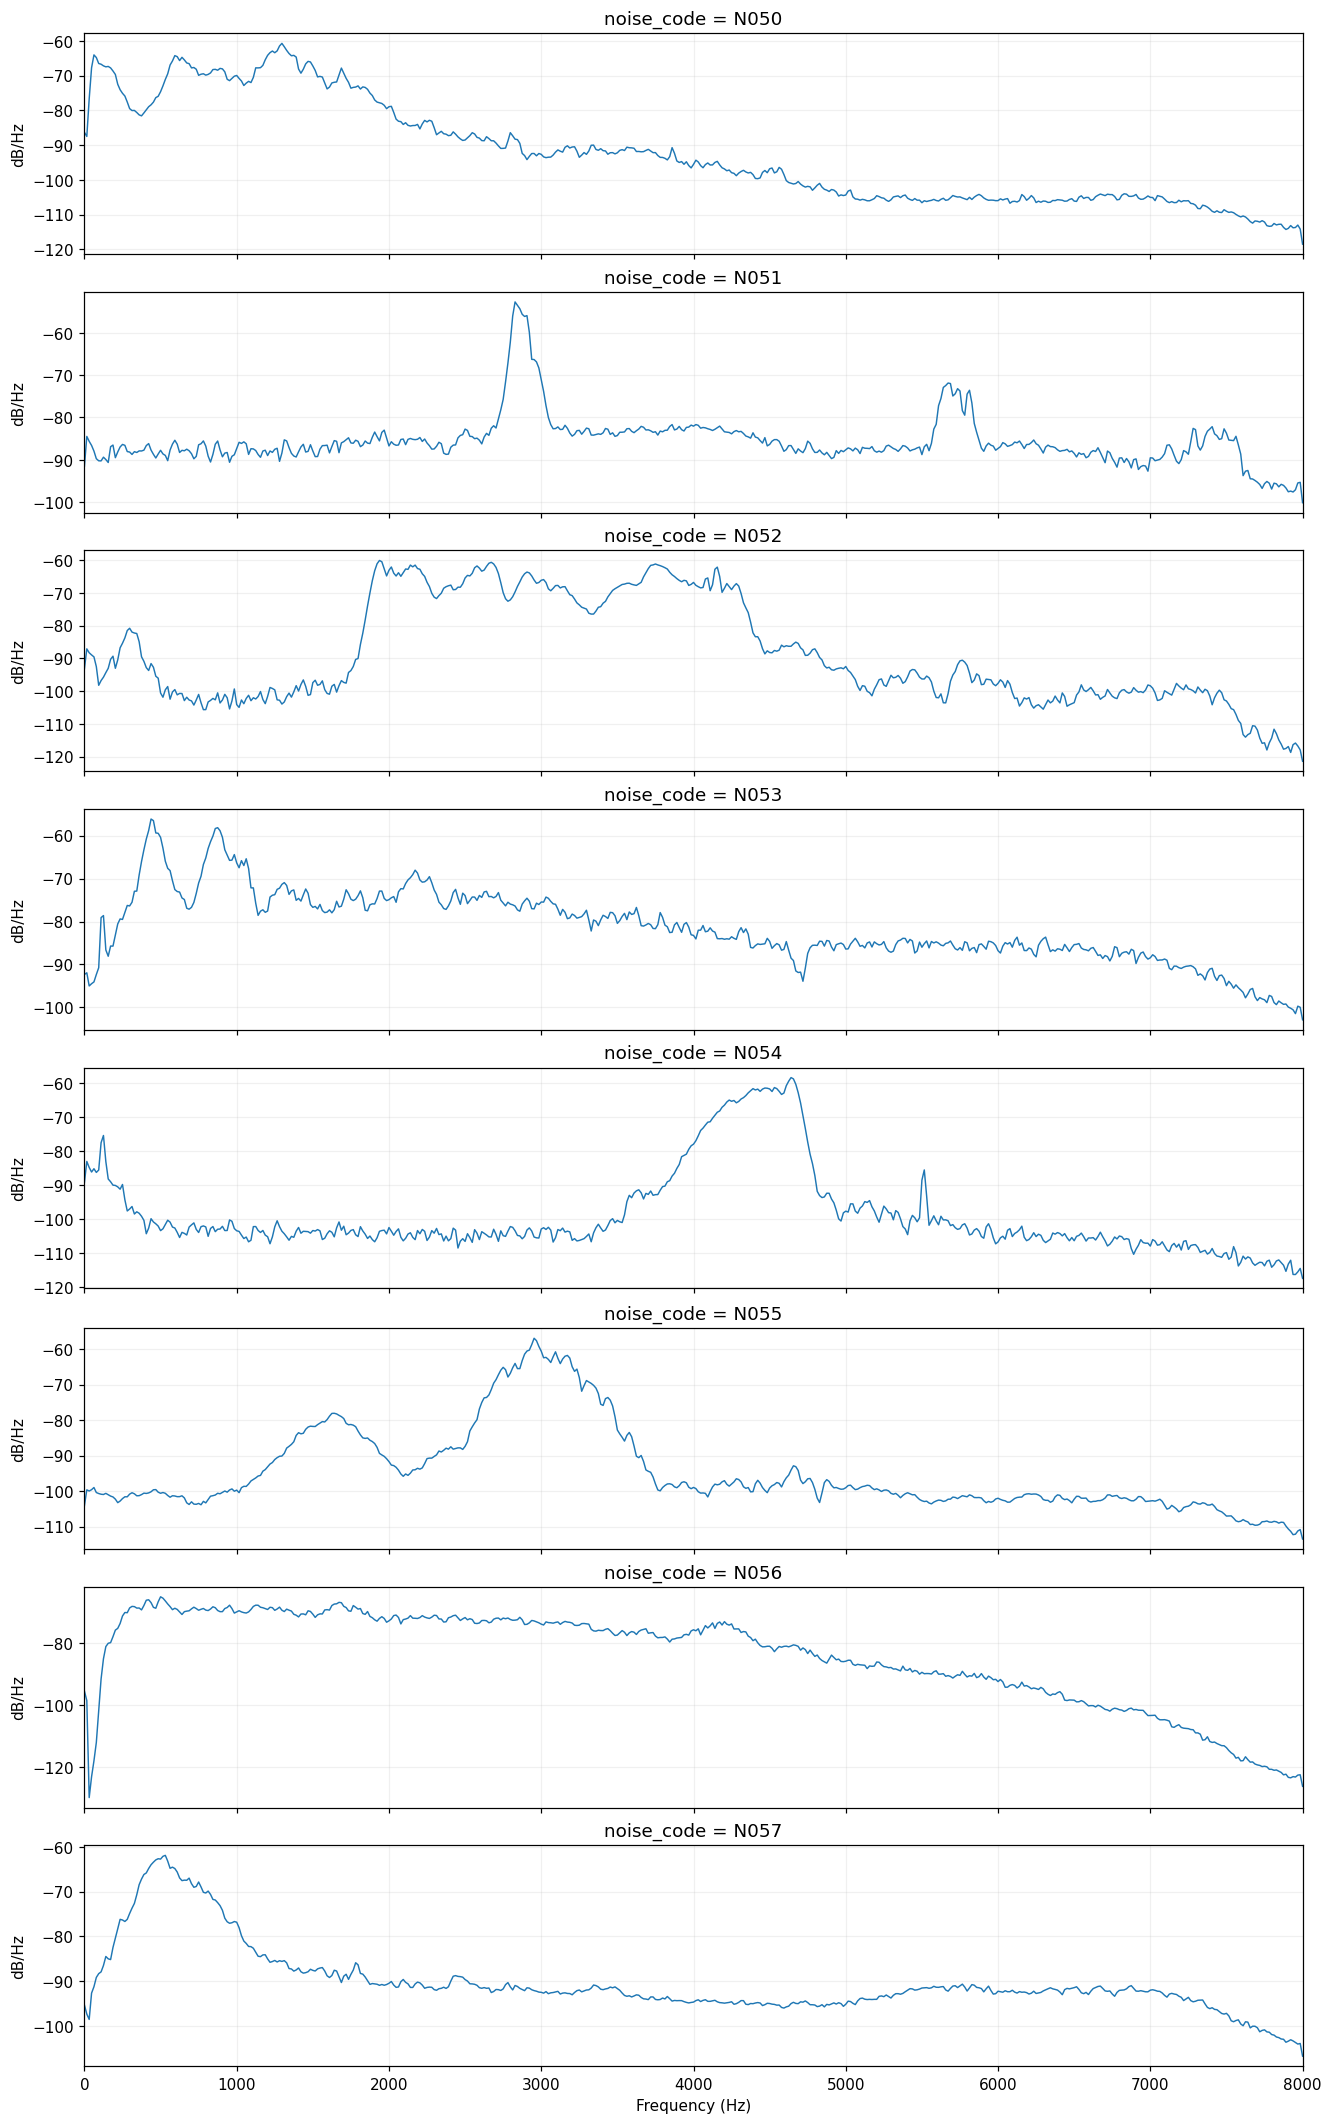

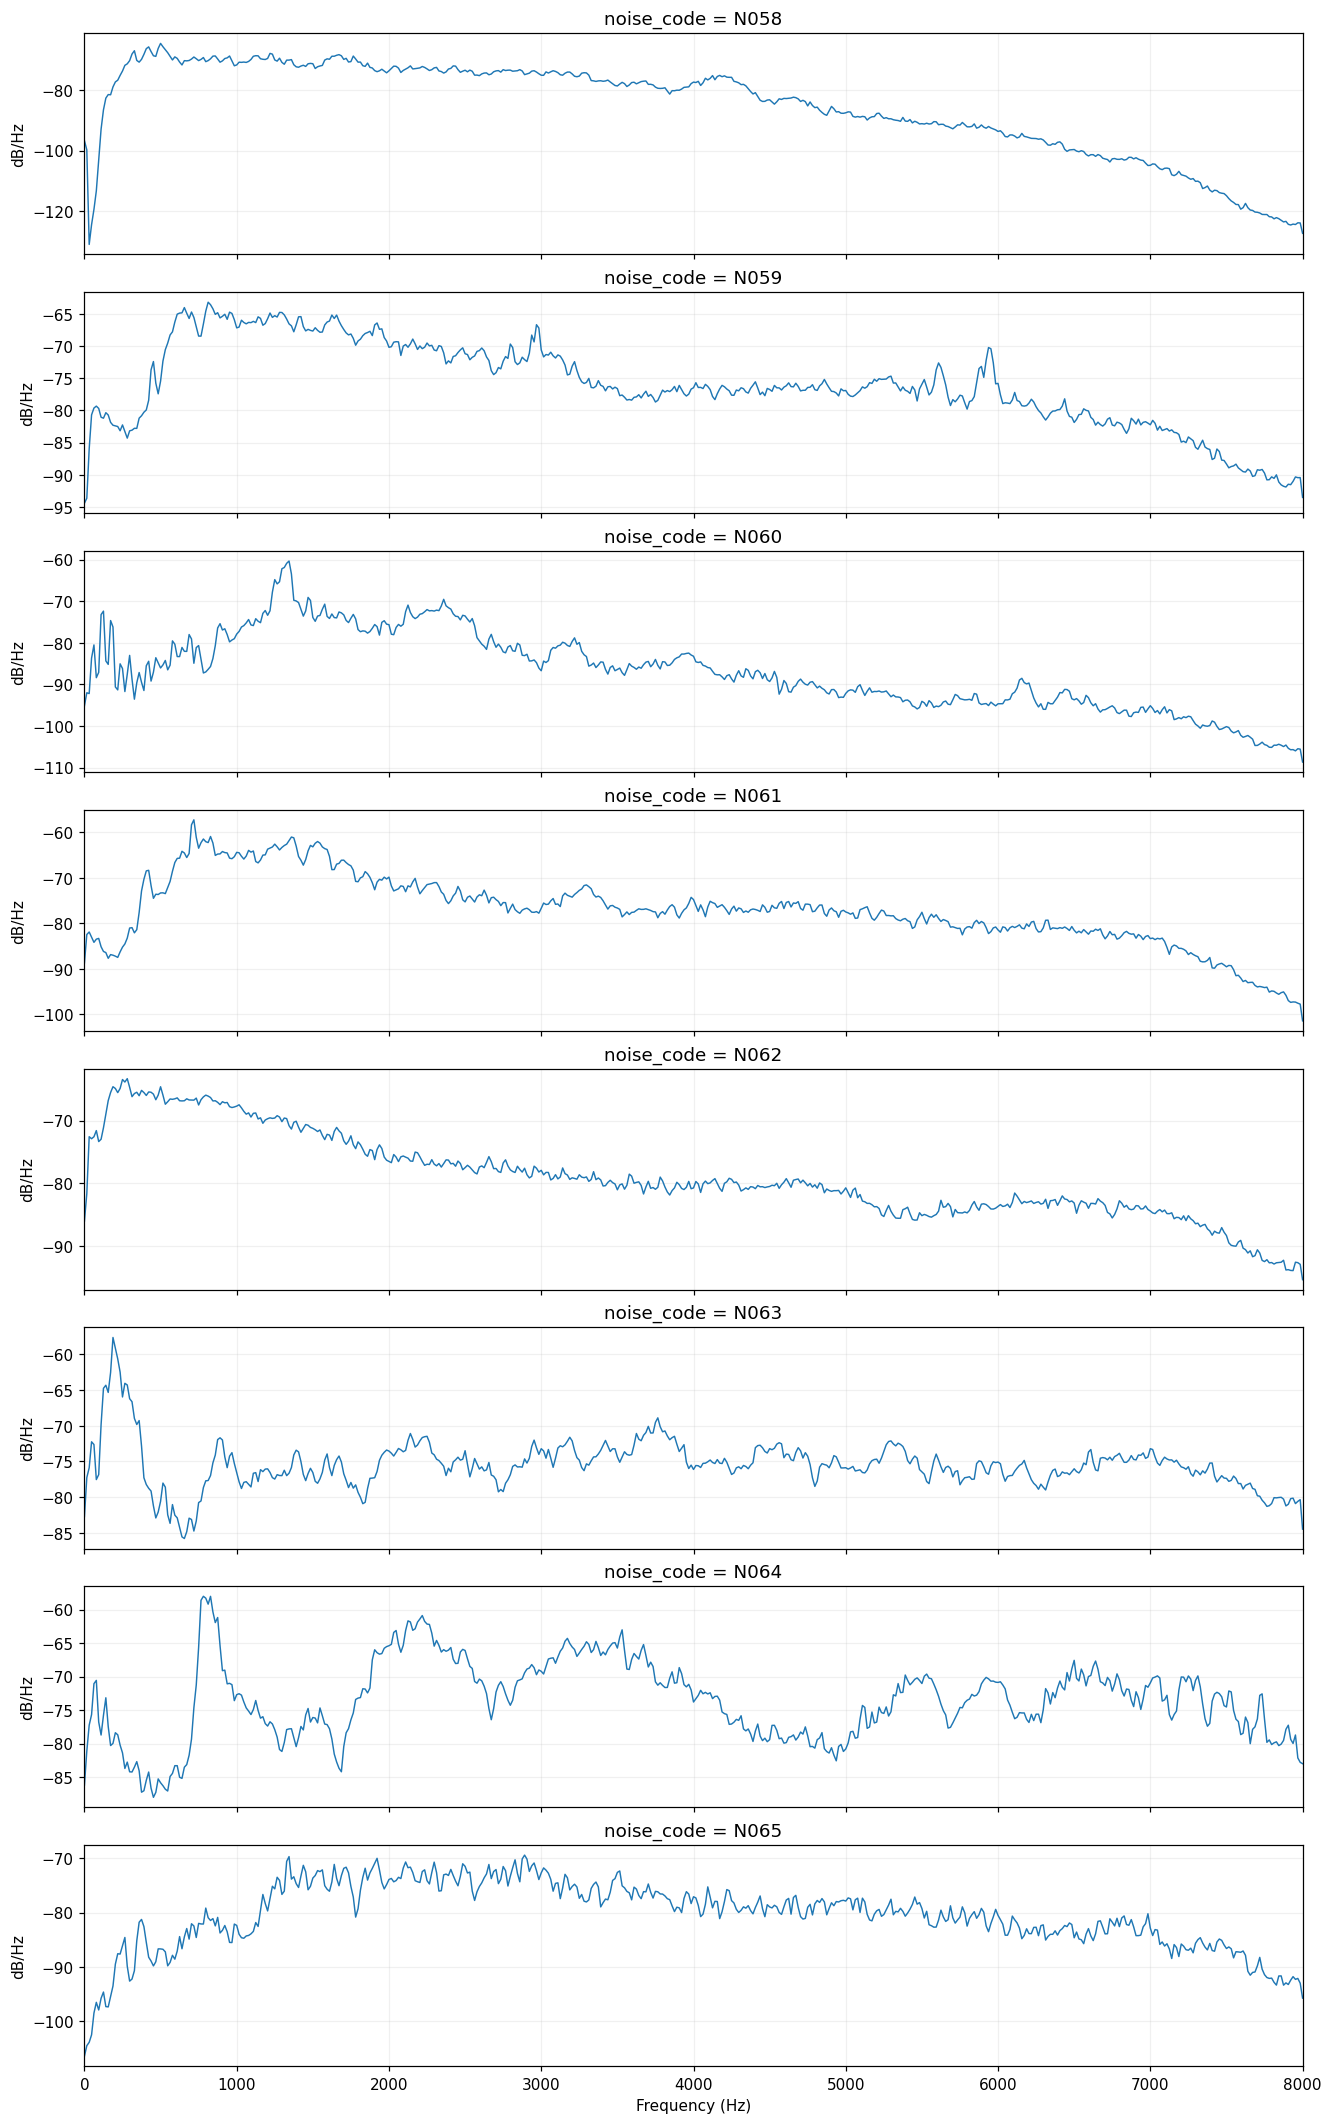

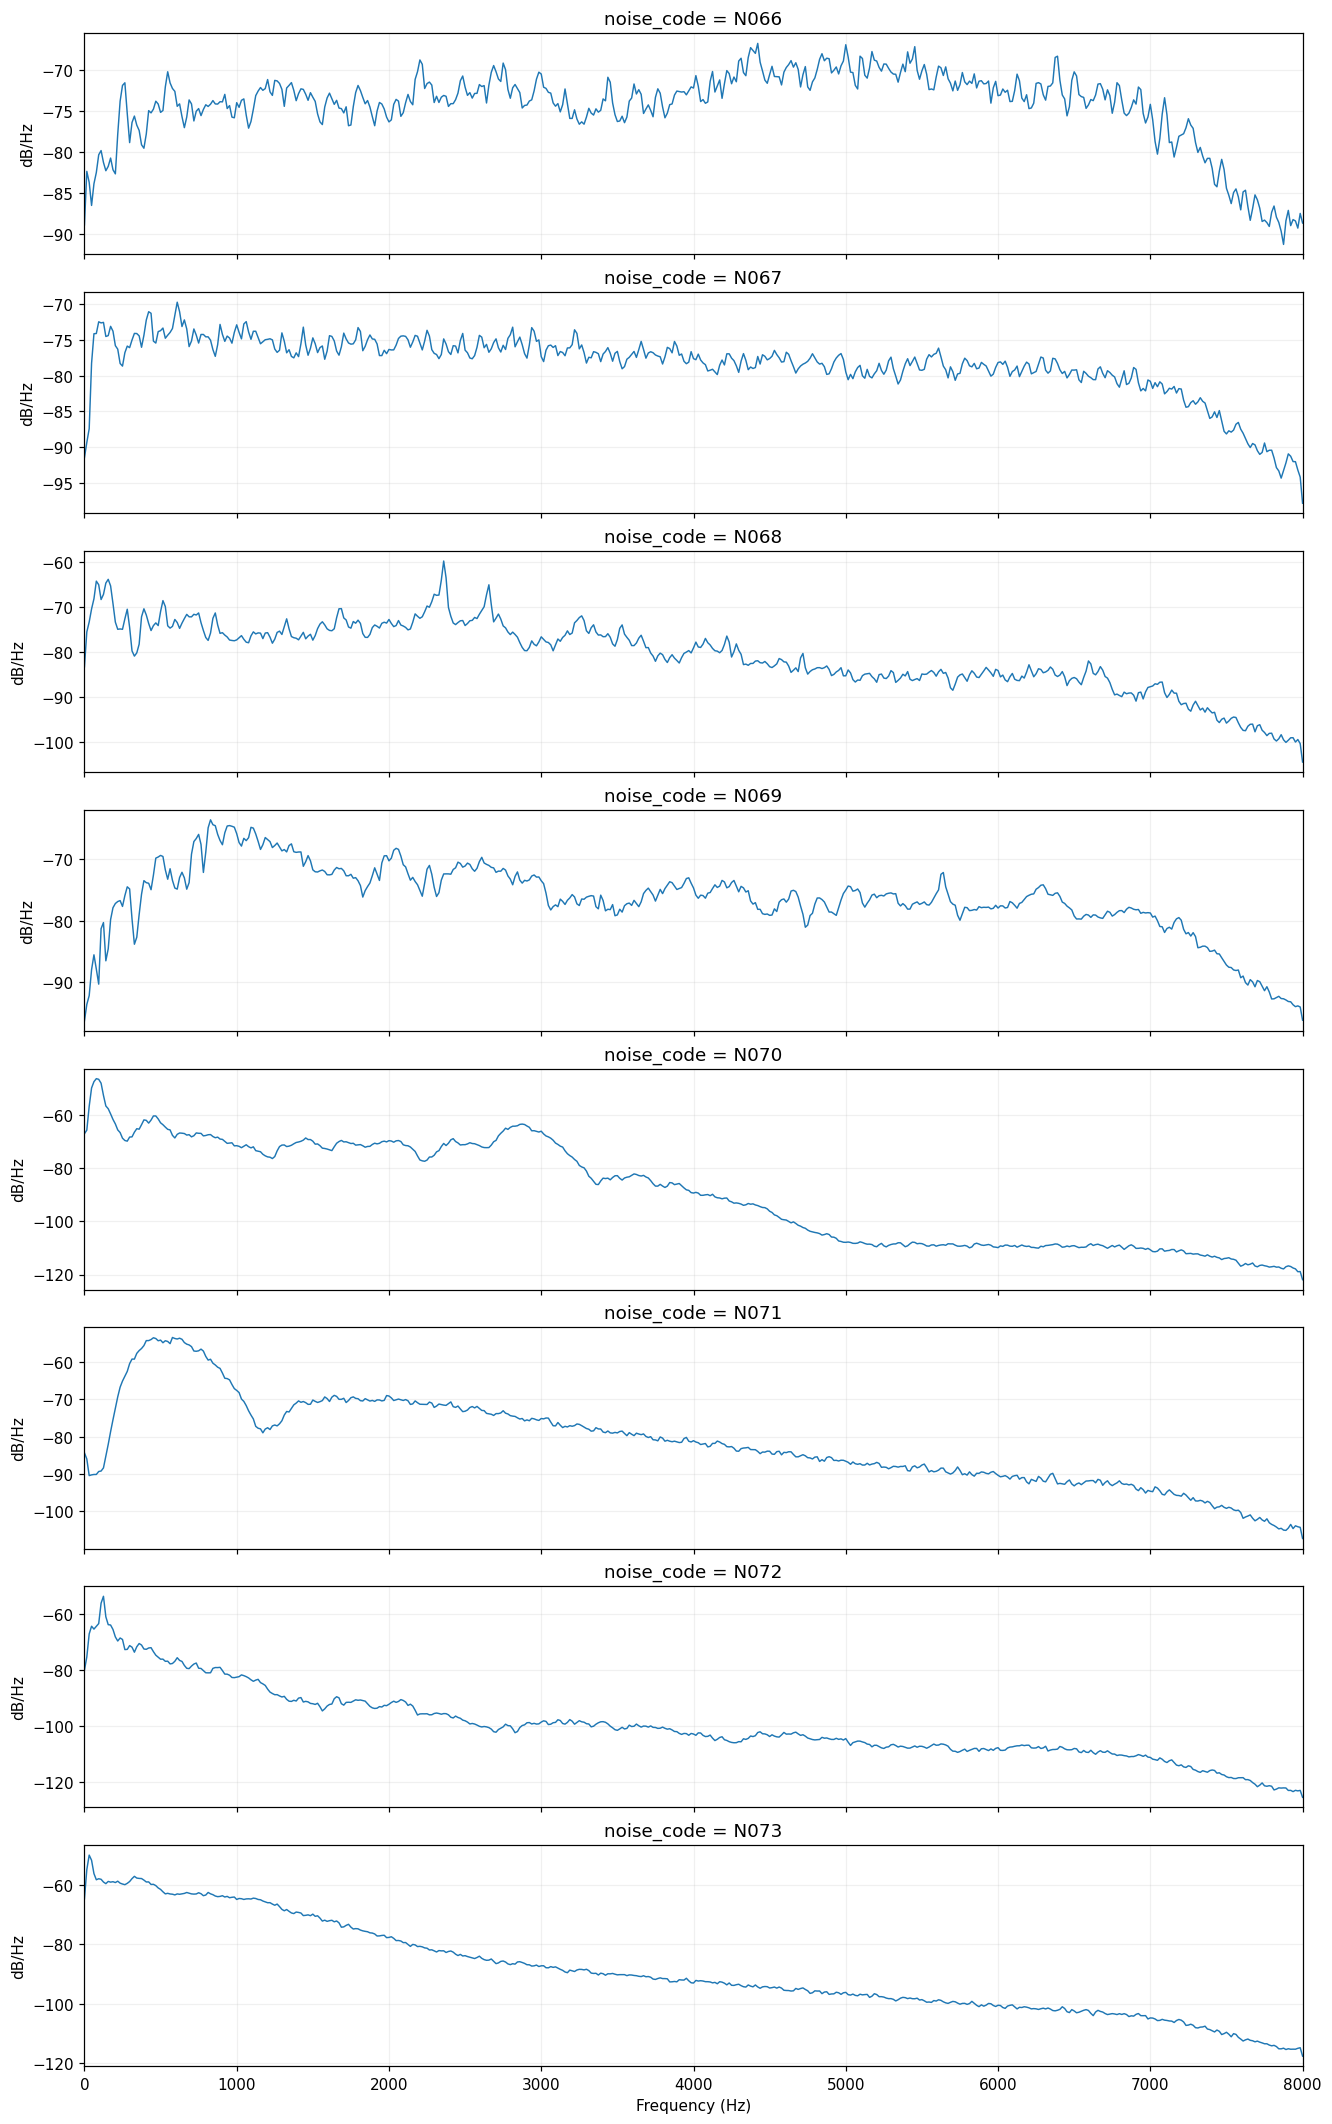

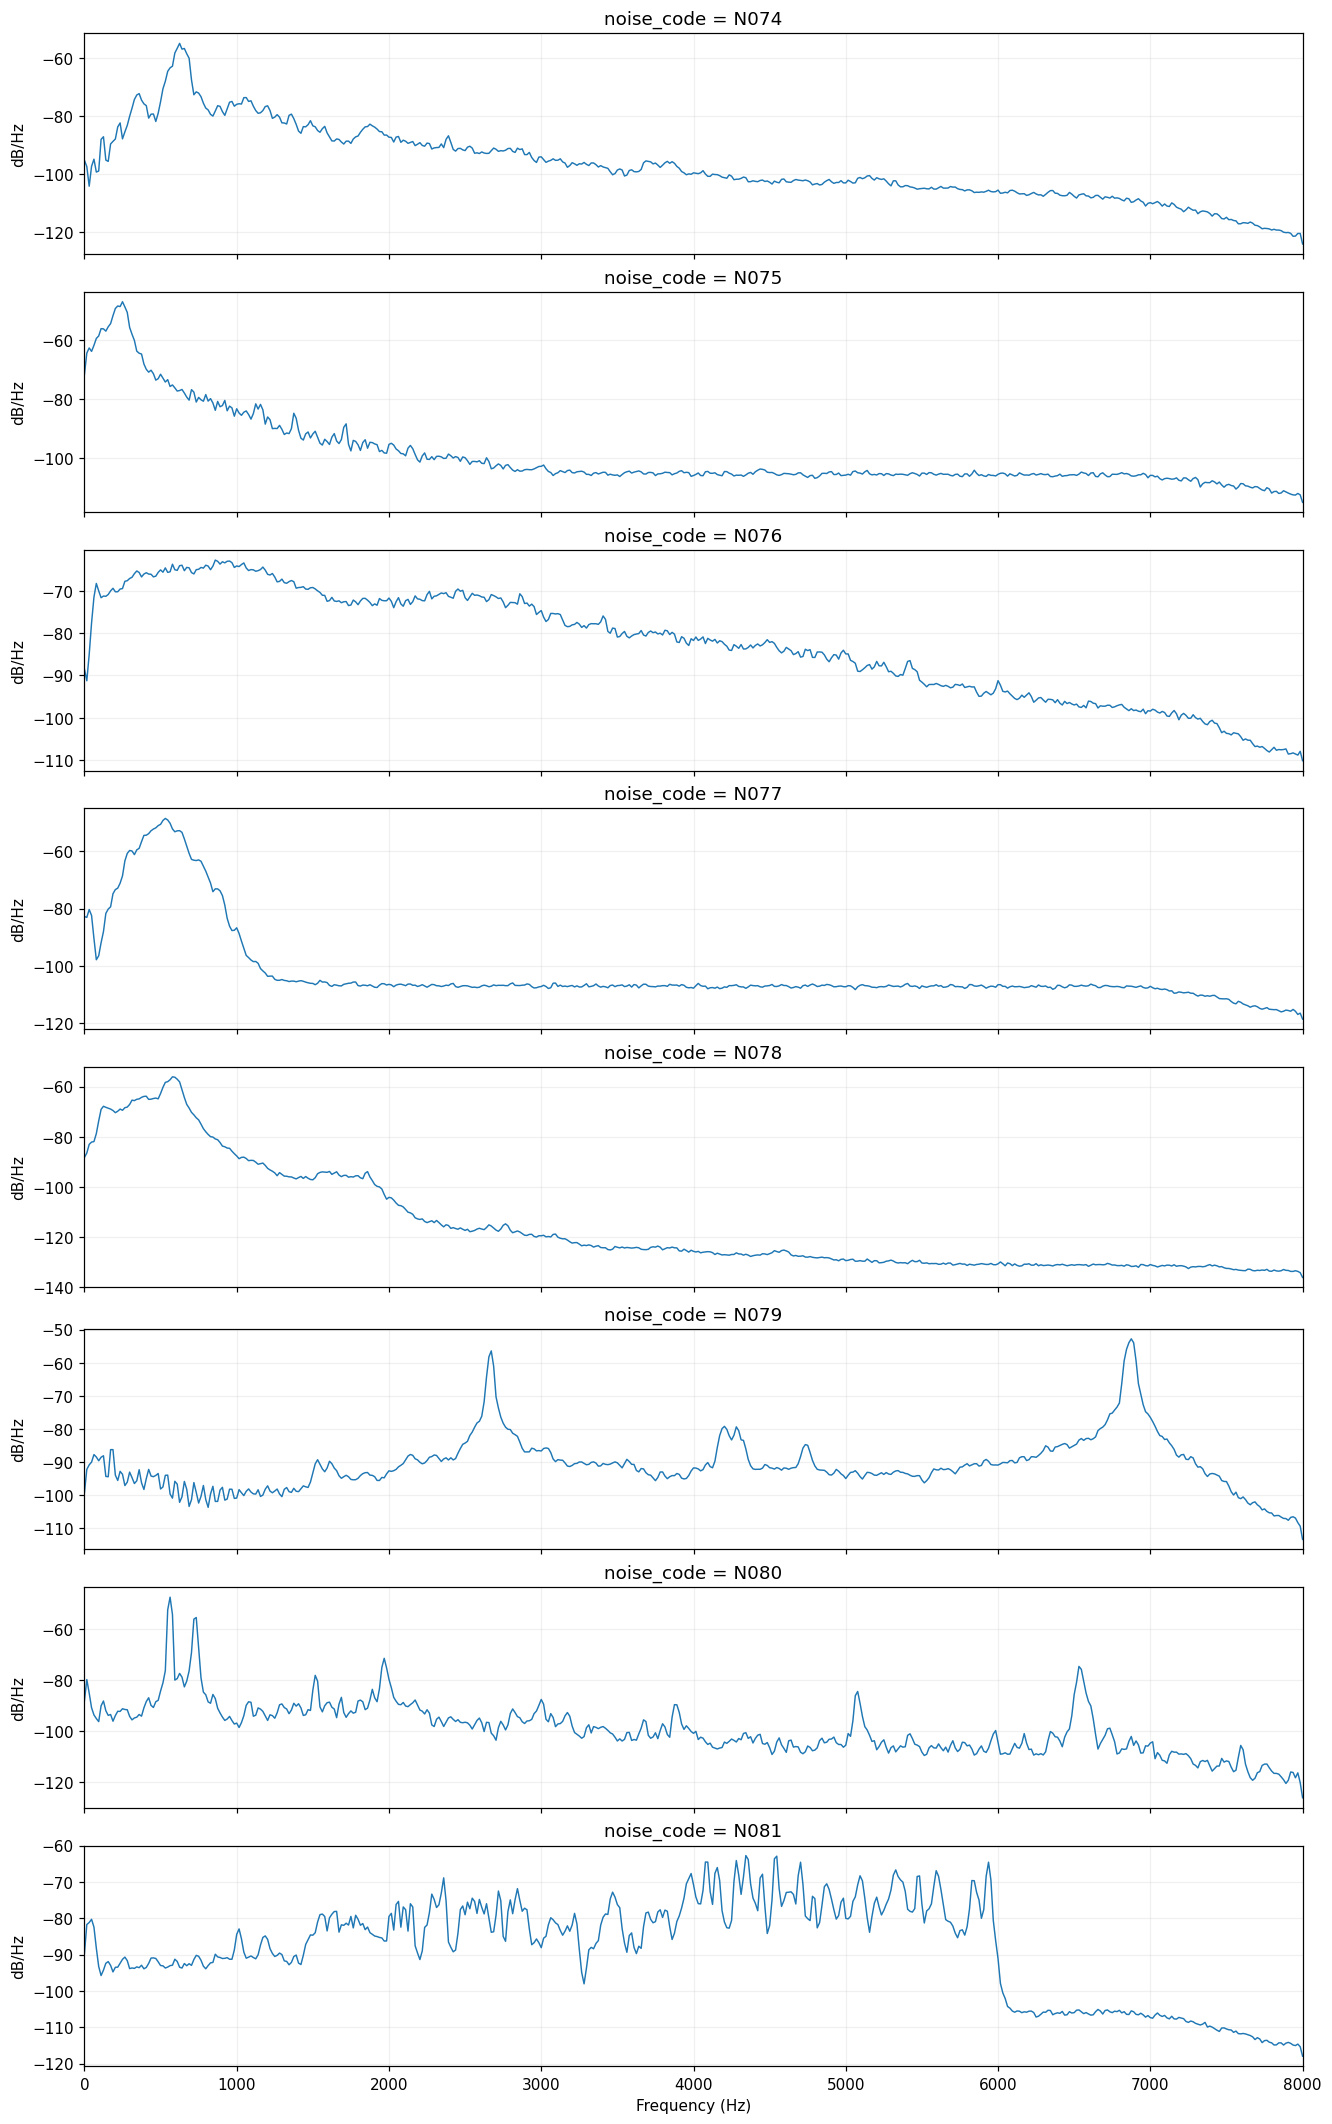

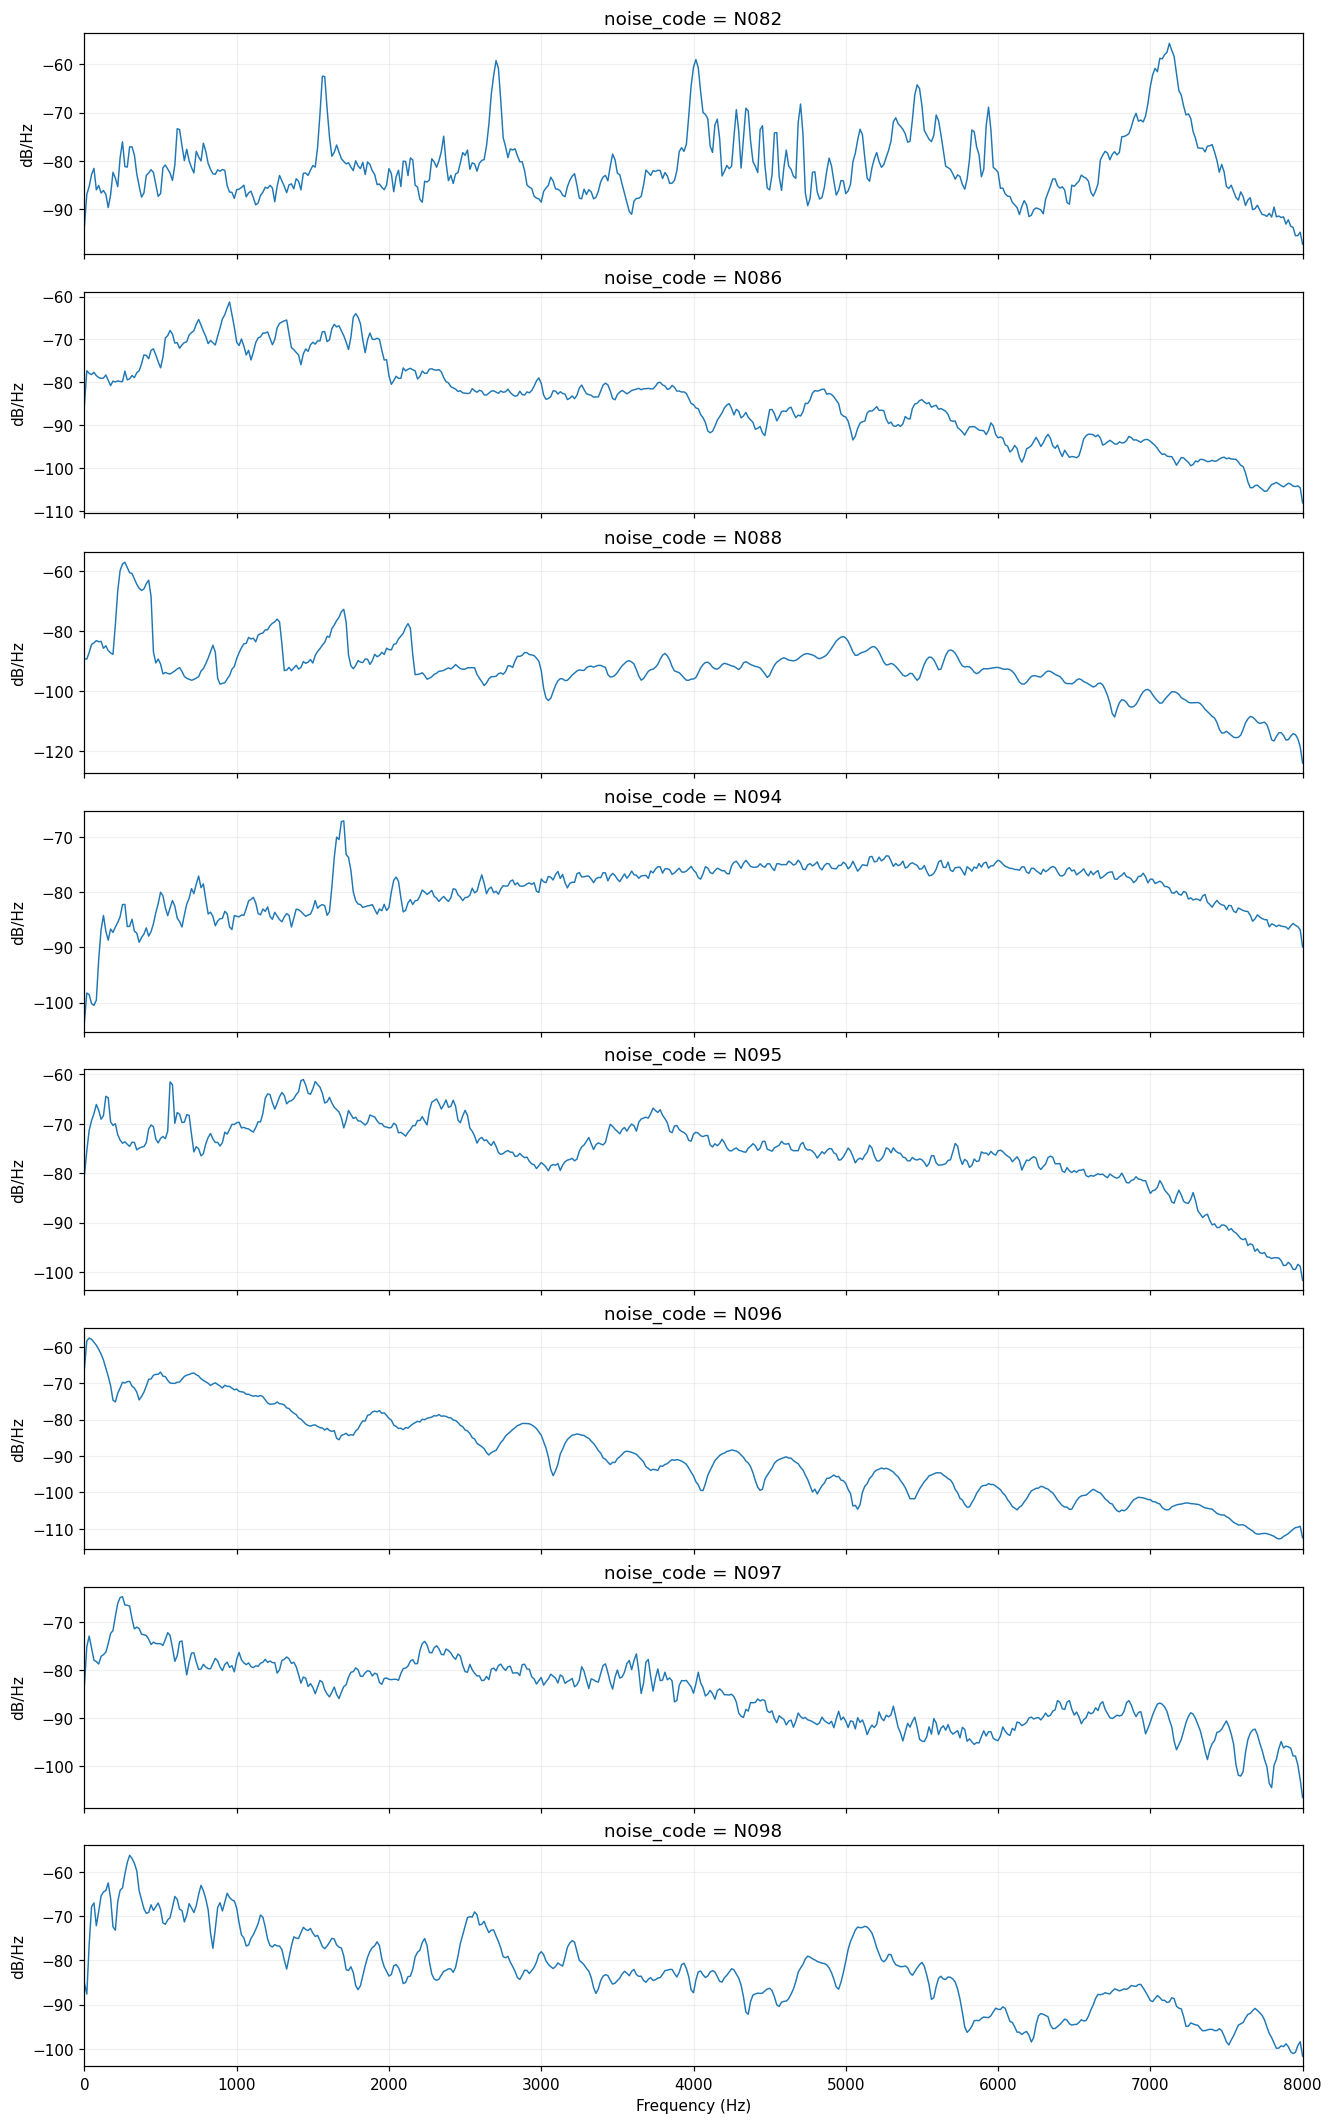

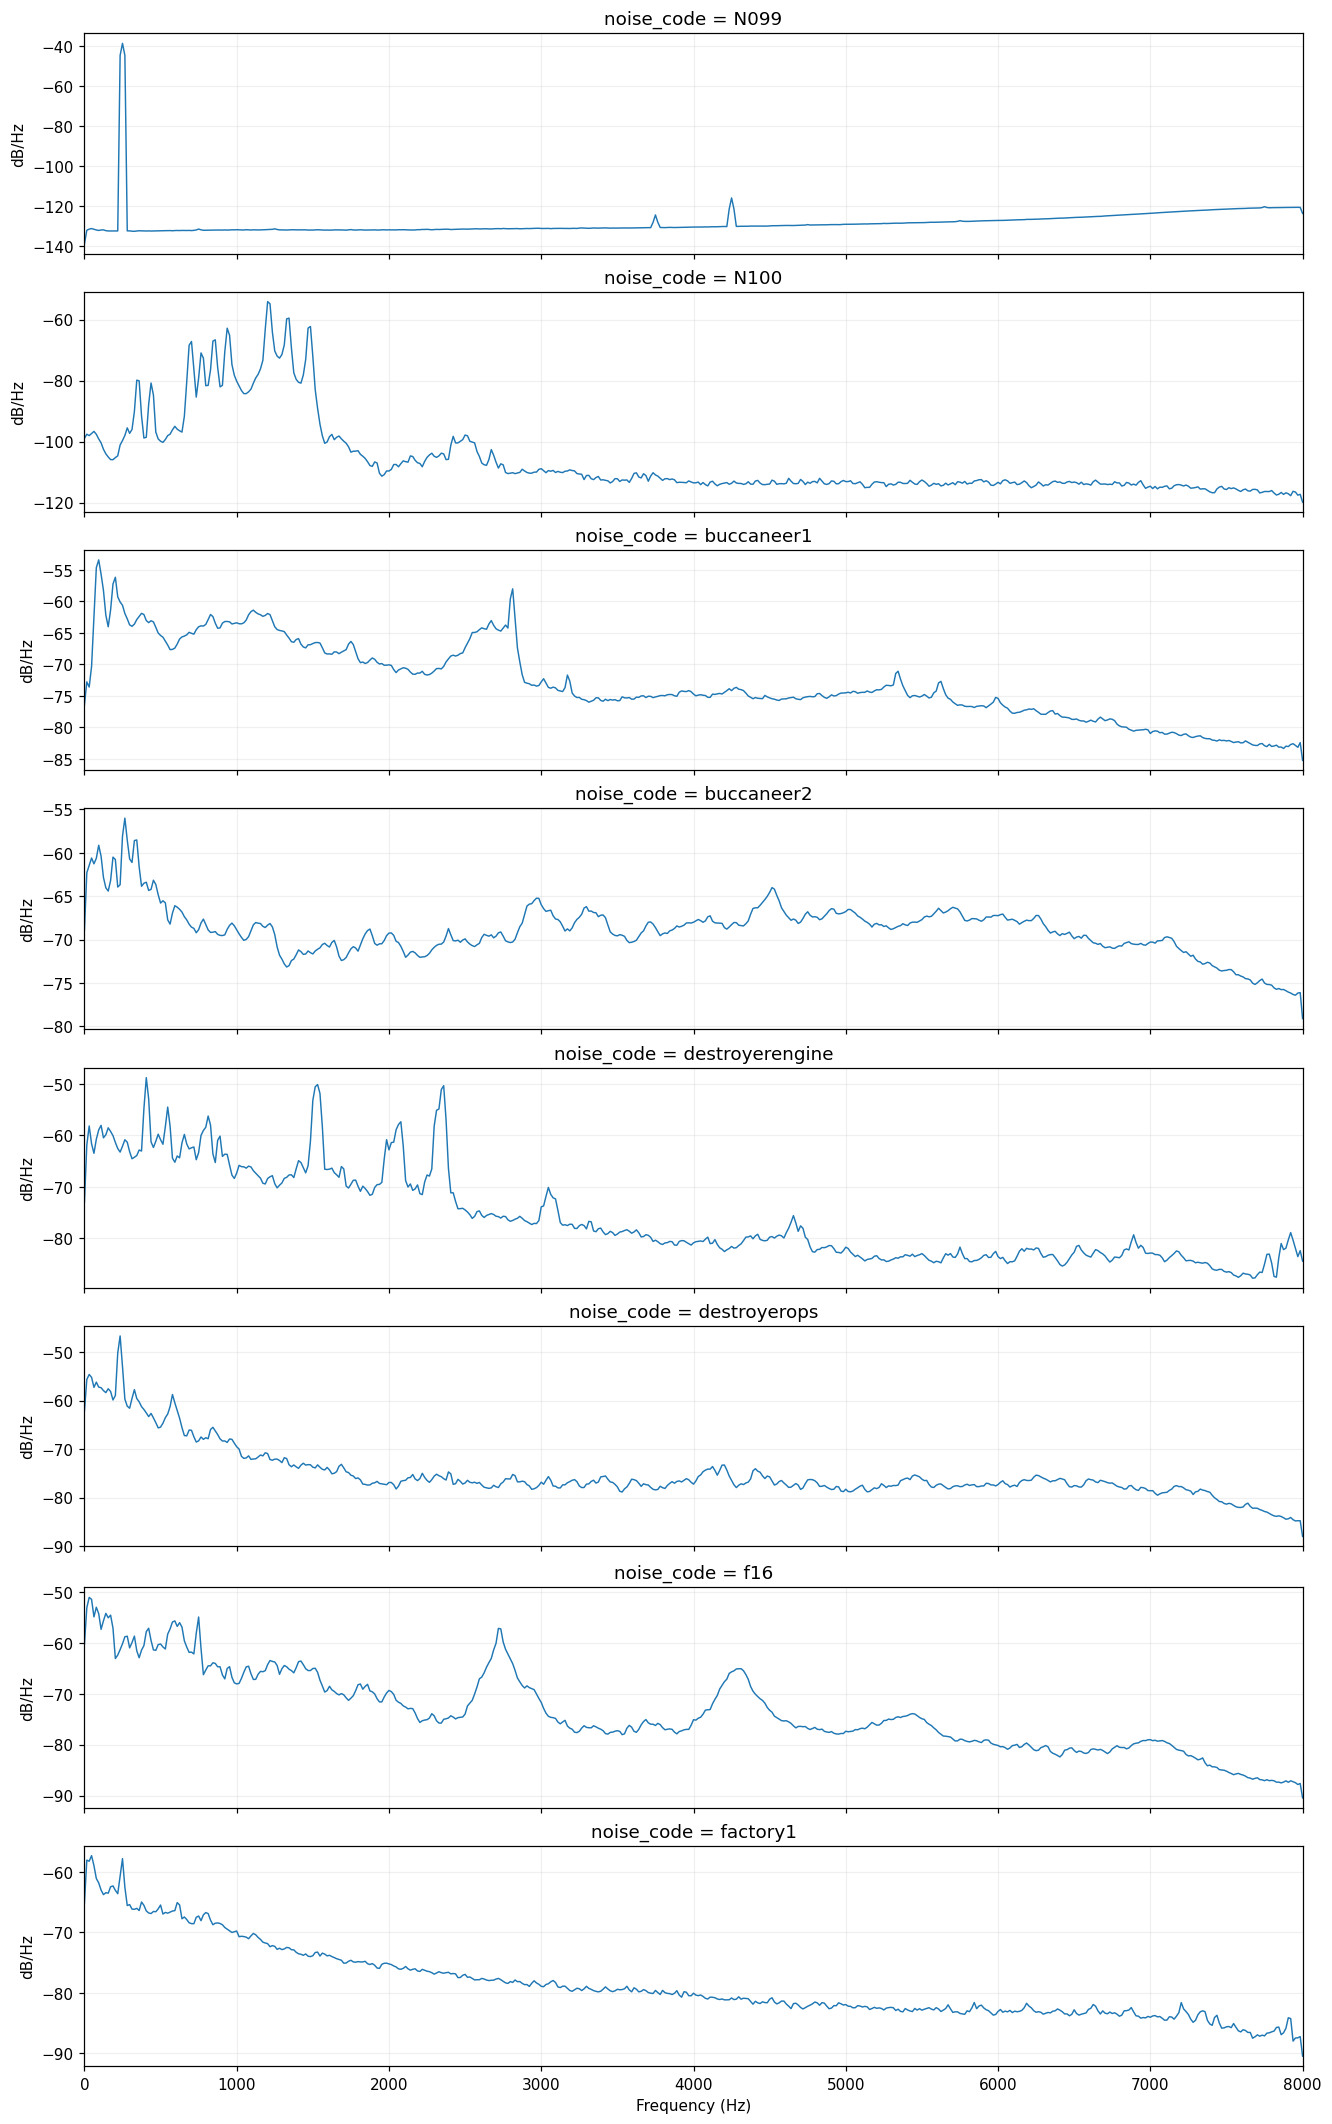

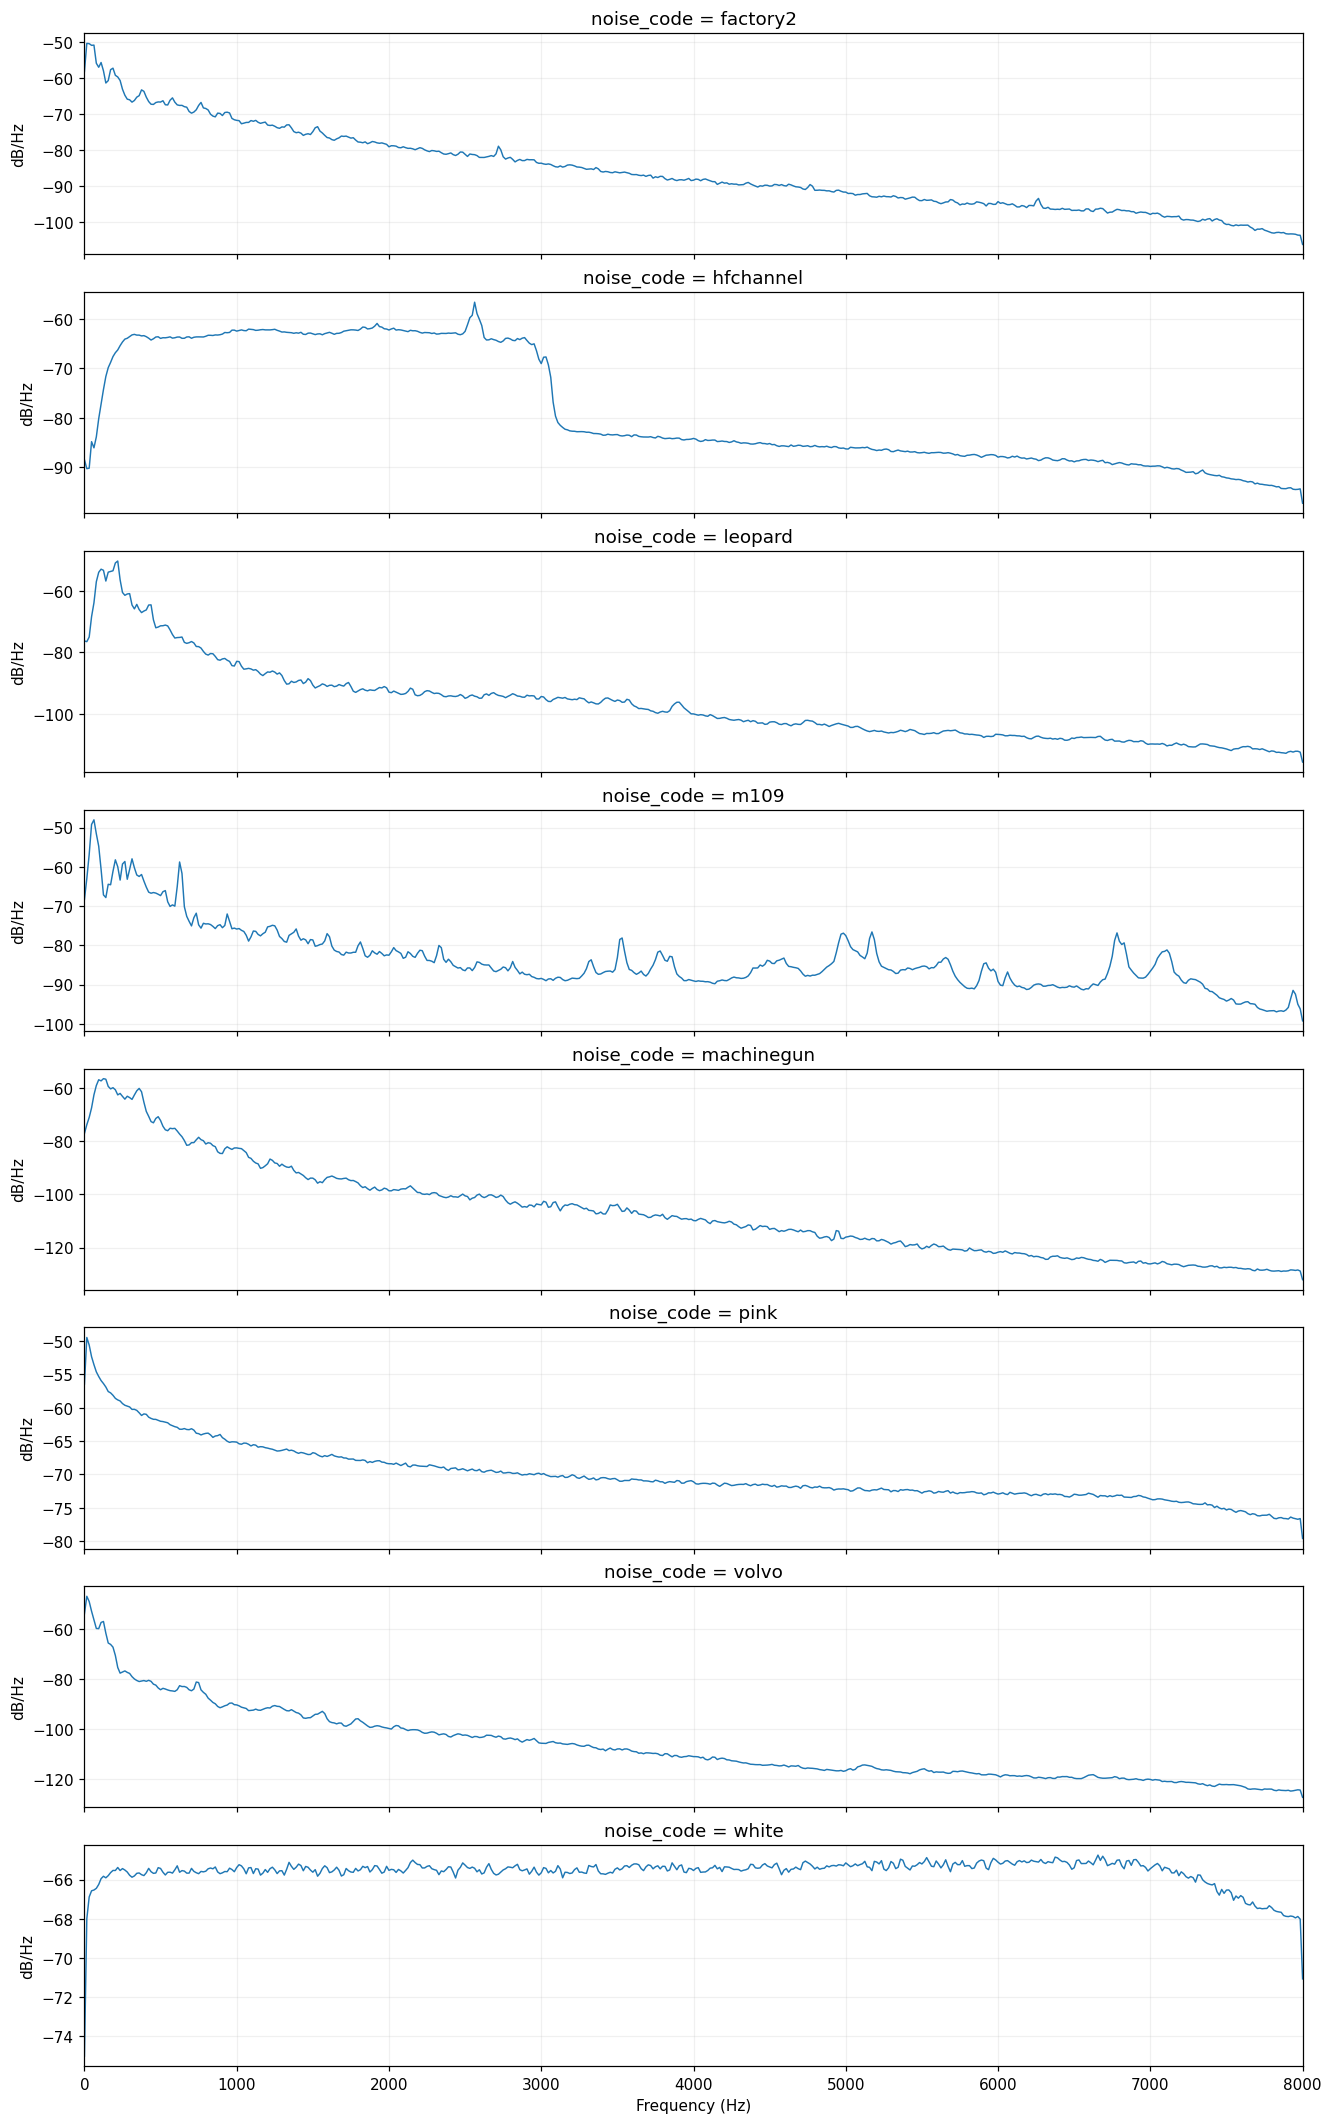

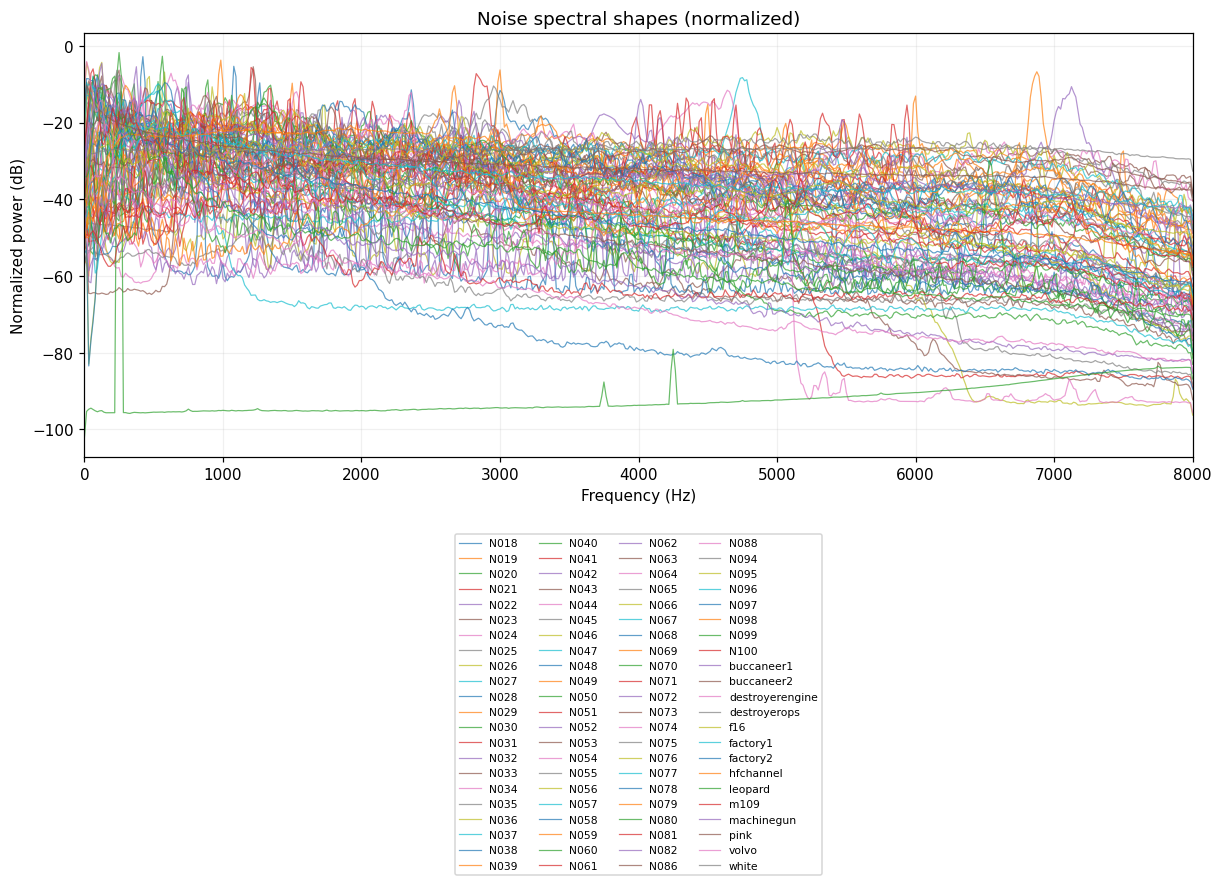

In [ ]:
# 그룹별 평균 PSD: 1장당 최대 8개씩 표시/저장
names=list(summary['group'].astype(str))
for page,start in enumerate(range(0,len(names),8),1):
    subset=names[start:start+8]
    fig,axes=plt.subplots(len(subset),1,figsize=(12,max(3,2.4*len(subset))),sharex=True,
                          constrained_layout=True)
    axes=np.atleast_1d(axes)
    for ax,name in zip(axes,subset):
        p=psd_by_group[name]['psd']
        ax.plot(frequency,10*np.log10(np.maximum(p,EPS)),lw=.95)
        ax.set(title=f'{GROUP_COLUMN} = {name}',ylabel='dB/Hz',xlim=(0,8000))
    axes[-1].set_xlabel('Frequency (Hz)')
    path=OUT/f'noise_psd_page_{page:02d}.png'
    fig.savefig(path,bbox_inches='tight');plt.show();plt.close(fig)

# 동일한 스케일로 normalized spectral shape 비교
fig,ax=plt.subplots(figsize=(13,5))
for name in names:
    shape=psd_by_group[name]['shape']
    ax.plot(frequency,10*np.log10(np.maximum(shape,EPS)),lw=.8,alpha=.7,label=name)
ax.set(title='Noise spectral shapes (normalized)',xlabel='Frequency (Hz)',ylabel='Normalized power (dB)',xlim=(0,8000))
ax.legend(fontsize=7,ncol=4,loc='upper center',bbox_to_anchor=(.5,-.17))
fig.savefig(OUT/'noise_psd_overlay.png',bbox_inches='tight');plt.show();plt.close(fig)

## Work 6. 각 잡음 유형의 대표 스펙트로그램

그룹마다 첫 Train 음성을 선택하고, `Noisy − Clean` 잡음만 같은 dB 범위로 시각화합니다. 그림별 색상 기준은 해당 파형의 최대 STFT 크기(상대 dB)이므로 **그림 간 절대 크기는 비교하지 말고 패턴을 비교**하세요.

In [ ]:
for group,group_df in tqdm(train.groupby(GROUP_COLUMN),desc='Spectrograms'):
    r=group_df.iloc[0]
    _,_,noise,sr=load_pair(r)
    ff,tt,mag=stft_mag(noise,sr)
    db=20*np.log10(np.maximum(mag,EPS)/max(float(mag.max()),EPS))
    fig,ax=plt.subplots(figsize=(10,3.2),constrained_layout=True)
    im=ax.pcolormesh(tt,ff/1000,db,shading='auto',cmap='magma',vmin=-80,vmax=0)
    ax.set(title=f'{GROUP_COLUMN}: {group} | {r["noise_category"]} | {r["segment_id"]}',
           xlabel='Time (s)',ylabel='Frequency (kHz)')
    fig.colorbar(im,ax=ax,label='dB relative to this noise peak')
    safe=''.join(c if c.isalnum() or c in '-_' else '_' for c in str(group))
    fig.savefig(OUT/f'spectrogram_{safe}.png',bbox_inches='tight')
    plt.close(fig)
print('저장된 스펙트로그램:',len(list(OUT.glob('spectrogram_*.png'))))

Spectrograms:   0%|          | 0/88 [00:00<?, ?it/s]

저장된 스펙트로그램: 88


## Work 7. 결과 ZIP 저장 → ChatGPT에 업로드

아래 셀 실행 후 만들어진 `noise_analysis_results.zip`을 이 채팅에 올려주세요. 특히 `noise_summary.csv`, `noise_psd_page_*.png`, `spectrogram_*.png`를 보고 잡음별 필터 전략을 제안할 수 있습니다.

**주의:** 여기서는 필터를 학습하거나 Validation 점수를 최적화하지 않습니다. 구조 분석만 수행합니다.

In [ ]:
zip_path=OUT.parent/'noise_analysis_results.zip'
with zipfile.ZipFile(zip_path,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT.iterdir()):
        if p.is_file(): z.write(p,arcname=p.name)
print('ZIP:',zip_path,'| 파일 수:',len(list(OUT.iterdir())))
try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print('로컬 환경에서는 위 ZIP 경로에서 파일을 가져오세요.')

ZIP: /content/noise_analysis_results.zip | 파일 수: 104


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>